# CLOVERS: heterogeneity of the treatment effect

First part of the analysis: does the effect of the restrictive fluid strategy differ between patients? All analyses use the 1,540 patients who did not withdraw consent.

The three approaches are interaction tests in three subgroups (septic shock, pre-existing renal impairment, ARDS at randomisation) with Holm correction, a Fisher randomisation test of a constant treatment effect with its power estimated by simulation, and individual effects predicted by BART, with a calibration test repeated over 100 random splits of the data.

The primary outcome is being alive and discharged by day 28, and the secondary outcome is 90-day mortality.

The notebook reads the BioLINCC files `DATASET.csv` and `DERIVED.csv` from `data/`. It was run in two sessions (April and September 2026), which is why the execution counts are not in order.

## Figure 2

This cell draws Figure 2 on its own. Panel a recomputes the subgroup interactions from `DATASET.csv` and panel b reads the BART predictions that section 10 writes to `_bart_work/`, so it has to be run after section 10.

Patients: 1540 (1540)
       ck                            sg   coef     p  p_holm   n0  n1
  primary                  Septic shock -0.066 0.847   1.000 1370 170
  primary Pre-existing renal impairment  0.452 0.199   0.598 1368 172
  primary         ARDS at randomisation -0.250 0.693   1.000 1498  42
mortality                  Septic shock -0.086 0.800   1.000 1370 170
mortality Pre-existing renal impairment -0.705 0.042   0.125 1368 172
mortality         ARDS at randomisation  0.378 0.553   1.000 1498  42
  expected: -0.066 / 0.847, +0.452 / 0.199, -0.250 / 0.693, then -0.086 / 0.800, -0.705 / 0.042 (Holm 0.125), +0.378 / 0.553
BART: n 1540 (1540) | SD 0.0038 (0.0038) | Q10-Q90 0.0099 (0.0099) | calibration p 0.8356 (0.8356)


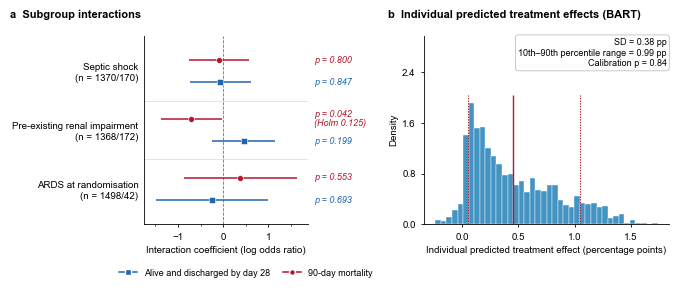

Saved: output_hte\figure2_hte_summary (.pdf, .png)


In [1]:
# Figure 2 of the paper, drawn in a single cell.
# Panel a: interactions recomputed from DATASET.csv, with the definitions of sections 2 and 7.
# Panel b: individual BART predictions written to ./_bart_work/ by the BART cell (section 10).
# Full Critical Care width (170 mm), 600 dpi, vector PDF, independent of the notebook's seaborn style.
def _figure2(dataset_path, bart_dir='_bart_work', out_dir='output_hte'):
    from pathlib import Path
    import numpy as np
    import pandas as pd
    import statsmodels.formula.api as smf
    from statsmodels.stats.multitest import multipletests

    bart_dir, out_dir = Path(bart_dir), Path(out_dir)
    for f in (bart_dir / 'bart_icate.csv', bart_dir / 'bart_data.csv'):
        if not f.exists():
            raise FileNotFoundError(f"{f.resolve()} not found: run the BART cell of this notebook first")
    out_dir.mkdir(exist_ok=True)

    # Panel a: subgroups and interactions
    cols = ['id', 'intervalname', 'term_wd', 'rand_trt', 'term_d90stat', 'term_disch', 'term_dischdt',
            'term_deathdt', 'blvaso_yn', 'labs_lactate', 'charl_kidney', 'medhx_cdialysisyn', 'ardshx_randyn']
    raw = pd.read_csv(dataset_path, usecols=cols, low_memory=False)
    raw = raw[~raw['id'].isin(raw.loc[raw['term_wd'] == 'Yes', 'id'].unique())]
    b = raw[raw['intervalname'] == 'Baseline'].groupby('id').first()
    trt = b['rand_trt']
    d = pd.DataFrame(index=b.index)
    d['restrictive_fluid'] = ((trt == 2) if pd.api.types.is_numeric_dtype(trt)
                              else (trt == 'Restrictive Fluid Group')).astype(int)
    d['mortality_90d'] = (b['term_d90stat'] == 'Dead').astype(int)
    disch = pd.to_numeric(b['term_dischdt'], errors='coerce')
    death = pd.to_numeric(b['term_deathdt'], errors='coerce')
    ad = ((b['term_disch'] == 'Yes') & (disch <= 28) & (death.isna() | (death > 28))).astype(float)
    ad[b['term_disch'].isna()] = np.nan
    d['alive_discharged_28d'] = ad
    d['sg_shock'] = ((b['blvaso_yn'] == 'Yes') & (pd.to_numeric(b['labs_lactate'], errors='coerce') > 2)).astype(int)
    d['sg_renal'] = (b['charl_kidney'].isin(['Present', 'Present with dialysis'])
                     | (b['medhx_cdialysisyn'] == 'Yes')).astype(int)
    d['sg_ards'] = (b['ardshx_randyn'] == 'Yes').astype(int)
    print(f"Patients: {len(d)} (1540)")

    subgroups = [('Septic shock', 'sg_shock'), ('Pre-existing renal impairment', 'sg_renal'),
                 ('ARDS at randomisation', 'sg_ards')]
    rows = []
    for ck, y in [('primary', 'alive_discharged_28d'), ('mortality', 'mortality_90d')]:
        block = []
        for lab, sg in subgroups:
            dd = d[['restrictive_fluid', y, sg]].dropna().rename(columns={sg: 'subgroup_bin'})
            fit = smf.logit(f"{y} ~ restrictive_fluid * subgroup_bin", data=dd).fit(disp=0)
            t = 'restrictive_fluid:subgroup_bin'
            block.append(dict(ck=ck, sg=lab, coef=fit.params[t], se=fit.bse[t], p=fit.pvalues[t],
                              n0=int((dd['subgroup_bin'] == 0).sum()), n1=int((dd['subgroup_bin'] == 1).sum())))
        holm = multipletests([r['p'] for r in block], method='holm')[1]
        for r, h in zip(block, holm):
            r['p_holm'] = h
        rows += block
    pa = pd.DataFrame(rows)
    pa['lo'], pa['hi'] = pa['coef'] - 1.96 * pa['se'], pa['coef'] + 1.96 * pa['se']
    print(pa[['ck', 'sg', 'coef', 'p', 'p_holm', 'n0', 'n1']].round(3).to_string(index=False))
    print("  expected: -0.066 / 0.847, +0.452 / 0.199, -0.250 / 0.693, then -0.086 / 0.800, "
          "-0.705 / 0.042 (Holm 0.125), +0.378 / 0.553")

    # Panel b: individual predictions and calibration test
    ic = pd.read_csv(bart_dir / 'bart_icate.csv')
    bd = pd.read_csv(bart_dir / 'bart_data.csv', usecols=['_rowid', 'restrictive_fluid', 'alive_discharged_28d'])
    cal = bd.merge(ic[['_rowid', 'ICATE']], on='_rowid', how='left').dropna(subset=['ICATE', 'alive_discharged_28d'])
    cal['trt_x_icate'] = cal['restrictive_fluid'] * cal['ICATE']
    cal_p = smf.ols('alive_discharged_28d ~ restrictive_fluid + ICATE + trt_x_icate',
                    data=cal).fit(cov_type='HC3').pvalues['trt_x_icate']
    icate = ic['ICATE'].dropna().values
    print(f"BART: n {len(icate)} (1540) | SD {ic['ICATE'].std():.4f} (0.0038) | "
          f"Q10-Q90 {ic['ICATE'].quantile(.9) - ic['ICATE'].quantile(.1):.4f} (0.0099) | calibration p {cal_p:.4f} (0.8356)")

    _draw_figure2(pa, icate, cal_p, out_dir)
    print(f"Saved: {out_dir / 'figure2_hte_summary'} (.pdf, .png)")

def _draw_figure2(pa, icate, cal_p, out_dir, show=True):
    """Figure 2 at full Critical Care width (170 mm), independent of the notebook's seaborn style.
    Writes a vector PDF (embedded fonts) and a 600 dpi PNG, tightly cropped."""
    from pathlib import Path
    import numpy as np
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    from matplotlib.ticker import MultipleLocator, MaxNLocator

    rc = {'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'],
          'font.size': 7, 'axes.labelsize': 7, 'xtick.labelsize': 7, 'ytick.labelsize': 7,
          'legend.fontsize': 6.5, 'axes.grid': False, 'axes.linewidth': 0.6, 'axes.edgecolor': 'black',
          'xtick.major.width': 0.6, 'ytick.major.width': 0.6, 'xtick.minor.width': 0.5,
          'xtick.major.size': 2.5, 'ytick.major.size': 2.5, 'xtick.minor.size': 1.5,
          'pdf.fonttype': 42, 'ps.fonttype': 42}
    red, blue = '#b2182b', '#2166ac'
    names = ['Septic shock', 'Pre-existing renal impairment', 'ARDS at randomisation']
    W, H = 170 / 25.4, 72 / 25.4                      # inches
    fx, fy = (lambda v: v / W), (lambda v: v / H)     # inches to figure fraction
    with plt.style.context('default'), mpl.rc_context(rc):
        fig = plt.figure(figsize=(W, H))
        ax_a = fig.add_axes([fx(1.36), fy(0.65), fx(1.64), fy(1.885)])
        ax_b = fig.add_axes([fx(4.16), fy(0.65), fx(2.45), fy(1.885)])

        # Panel a
        ypos = np.arange(len(names))[::-1].astype(float)
        x_lo = min(pa['lo'].min() - 0.25, -1.75)
        x_hi = max(pa['hi'].max() + 0.25, 1.0)
        for k in range(len(names) - 1):
            ax_a.axhline(ypos[k] - 0.5, color='0.85', lw=0.5, zorder=0)
        ax_a.axvline(0, color='0.45', lw=0.6, ls='--', zorder=1)
        tr_p = mpl.transforms.blended_transform_factory(fig.transFigure, ax_a.transData)
        for ck, sgn, c, mk in [('primary', -1, blue, 's'), ('mortality', 1, red, 'o')]:
            for k, nm in enumerate(names):
                r = pa[(pa['ck'] == ck) & (pa['sg'] == nm)].iloc[0]
                y = ypos[k] + sgn * 0.19
                ax_a.plot([max(r['lo'], x_lo), min(r['hi'], x_hi)], [y, y], color=c, lw=1.1,
                          solid_capstyle='butt', zorder=2)
                ax_a.plot(r['coef'], y, marker=mk, color=c, ms=4.2, mec='white', mew=0.4, zorder=3)
                txt = f"p = {r['p']:.3f}" + (f"\n(Holm {r['p_holm']:.3f})" if r['p'] < 0.05 else '')
                fig.text(fx(3.06), y, txt, transform=tr_p, fontsize=6.5, color=c, style='italic',
                         ha='left', va='center', linespacing=1.1)
        prim = pa[pa['ck'] == 'primary'].set_index('sg')
        ax_a.set_xlim(x_lo, x_hi)
        ax_a.set_ylim(-0.6, len(names) - 0.4)
        ax_a.set_yticks(ypos)
        ax_a.set_yticklabels([f"{nm}\n(n = {prim.loc[nm, 'n0']}/{prim.loc[nm, 'n1']})" for nm in names])
        ax_a.tick_params(axis='y', length=0, pad=4)
        ax_a.xaxis.set_major_locator(MultipleLocator(1))
        ax_a.xaxis.set_minor_locator(MultipleLocator(0.5))
        ax_a.set_xlabel('Interaction coefficient (log odds ratio)', labelpad=3)
        for s in ('top', 'right'):
            ax_a.spines[s].set_visible(False)
        ax_a.legend(handles=[
            Line2D([0], [0], marker='s', color=blue, lw=1.1, ms=4.2, mec='white', label='Alive and discharged by day 28'),
            Line2D([0], [0], marker='o', color=red, lw=1.1, ms=4.2, mec='white', label='90-day mortality')],
            loc='upper center', bbox_to_anchor=(0.62, -0.215), ncol=2, frameon=False, handlelength=2.0,
            columnspacing=1.4, borderaxespad=0)

        # Panel b
        vals = np.asarray(icate) * 100
        counts, _, _ = ax_b.hist(vals, bins=40, density=True, color='#4393c3', edgecolor='white', lw=0.3, zorder=2)
        top_bars = counts.max()
        y_lines = top_bars * 1.06
        mean, q10, q90 = vals.mean(), np.percentile(vals, 10), np.percentile(vals, 90)
        ax_b.vlines(mean, 0, y_lines, color=red, lw=1.0, zorder=3)
        ax_b.vlines([q10, q90], 0, y_lines, color=red, lw=0.8, linestyles=(0, (1.2, 1.2)), zorder=3)
        ax_b.set_ylim(0, top_bars * 1.55)
        ax_b.set_xlim(min(vals.min(), -0.1) - 0.1, vals.max() + 0.1)
        ax_b.xaxis.set_major_locator(MultipleLocator(0.5))
        ax_b.yaxis.set_major_locator(MaxNLocator(4))
        ax_b.set_xlabel('Individual predicted treatment effect (percentage points)', labelpad=3)
        ax_b.set_ylabel('Density', labelpad=3)
        for s in ('top', 'right'):
            ax_b.spines[s].set_visible(False)
        ax_b.text(0.99, 0.99,
                  f"SD = {np.std(vals):.2f} pp\n10th\u201390th percentile range = {q90 - q10:.2f} pp\n"
                  f"Calibration p = {cal_p:.2f}",
                  transform=ax_b.transAxes, ha='right', va='top', fontsize=6.5, linespacing=1.25, zorder=5,
                  bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='0.7', lw=0.5))

        # Panel letters and titles, one line each
        for x, s in [(0.02, 'a  Subgroup interactions'),
                     (3.80, 'b  Individual predicted treatment effects (BART)')]:
            fig.text(fx(x), fy(H - 0.04), s, fontsize=8, fontweight='bold', ha='left', va='top')

        out_dir = Path(out_dir)
        out_dir.mkdir(exist_ok=True)
        base = out_dir / 'figure2_hte_summary'
        kw = dict(bbox_inches='tight', pad_inches=0.02)
        fig.savefig(str(base) + '.pdf', **kw)
        fig.savefig(str(base) + '.png', dpi=600, **kw)
        if show:
            plt.show()
        return fig

_figure2(globals().get('dataset_path',
                       "data/DATASET.csv"))

In [2]:
# R 4.4.3: BART is run through Rscript (section 10)
import os
r_home = r"C:\Program Files\R\R-4.4.3"
os.environ['R_HOME'] = r_home
r_bin_path = os.path.join(r_home, 'bin', 'x64')
os.environ['PATH'] = r_bin_path + ';' + os.environ.get('PATH', '')
if hasattr(os, 'add_dll_directory'):
    os.add_dll_directory(r_bin_path)

import shutil, subprocess, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import fisher_exact, mannwhitneyu, norm
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
import statsmodels.api as sm
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer
from tqdm.auto import tqdm
from typing import Dict, List, Tuple, Optional, Set

warnings.filterwarnings('ignore')

# Plotting defaults
plt.rcParams.update({
    'font.family': 'Arial', 'font.size': 10,
    'axes.labelsize': 11, 'axes.titlesize': 12,
    'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'legend.fontsize': 9, 'figure.dpi': 300,
    'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42,
})
plt.style.use('seaborn-v0_8-whitegrid')


## 1. Configuration

In [3]:
# Configuration. The two BioLINCC files are expected in data/.
dataset_path = "data/DATASET.csv"
derived_path = "data/DERIVED.csv"

TREATMENT_VAR = "restrictive_fluid"
PRIMARY_OUTCOME = "alive_discharged_28d"     # primary outcome of the paper
SECONDARY_OUTCOME = "mortality_90d"          # secondary outcome

N_IMPUTATIONS = 20
N_PERMUTATIONS_FRT = 10000
N_BOOTSTRAP_BART = 5    # BART cross-fit folds
SEED = 42

OUTPUT_DIR = Path("./output_hte")
OUTPUT_DIR.mkdir(exist_ok=True)

print(f"Primary outcome:    {PRIMARY_OUTCOME}")
print(f"Secondary outcome:  {SECONDARY_OUTCOME}")
print(f"Imputation datasets: {N_IMPUTATIONS}")
print(f"FRT permutations: {N_PERMUTATIONS_FRT}")


Primary outcome:    alive_discharged_28d
Secondary outcome:  mortality_90d
Imputation datasets: 20
FRT permutations: 10000


## 2. Data and variables

Withdrawn patients are excluded. The randomisation location (five levels) stands in for the centre, which the de-identified dataset does not give, and is used as the permutation stratum.

In [4]:
# Load data and exclude withdrawn patients
df_raw = pd.read_csv(dataset_path, low_memory=False)
df_derived = pd.read_csv(derived_path, low_memory=False)

ids_withdrawn = df_raw.loc[df_raw['term_wd'] == 'Yes', 'id'].unique()
df_raw = df_raw[~df_raw['id'].isin(ids_withdrawn)]
df_derived = df_derived[~df_derived['id'].isin(ids_withdrawn)]

screening = df_raw[df_raw['intervalname'] == 'Screening'].copy()
baseline = df_raw[df_raw['intervalname'] == 'Baseline'].copy()
derived_baseline = df_derived[df_derived['intervalname'] == 'Baseline'].copy()

all_patient_ids = baseline['id'].unique()
n_total = len(all_patient_ids)

print("="*80)
print("CLOVERS HTE - DATA LOADING")
print("="*80)
print(f"Patients after excluding {len(ids_withdrawn)} withdrawn: {n_total}")


CLOVERS HTE - DATA LOADING
Patients after excluding 23 withdrawn: 1540


In [6]:
# Helper: baseline SOFA without GCS
def calculate_sofa_nogcs_baseline(data):
    sofa = pd.DataFrame(index=data.index)
    
    # Coagulation
    sofa['sofa_coag'] = 0
    sofa.loc[data['labs_platelets'].notna() & (data['labs_platelets'] <= 150), 'sofa_coag'] = 1
    sofa.loc[data['labs_platelets'].notna() & (data['labs_platelets'] <= 100), 'sofa_coag'] = 2
    sofa.loc[data['labs_platelets'].notna() & (data['labs_platelets'] <= 50), 'sofa_coag'] = 3
    sofa.loc[data['labs_platelets'].notna() & (data['labs_platelets'] <= 20), 'sofa_coag'] = 4
    
    # Liver
    sofa['sofa_liver'] = 0
    sofa.loc[data['labs_totalbili'].notna() & (data['labs_totalbili'] >= 1.2), 'sofa_liver'] = 1
    sofa.loc[data['labs_totalbili'].notna() & (data['labs_totalbili'] >= 2.0), 'sofa_liver'] = 2
    sofa.loc[data['labs_totalbili'].notna() & (data['labs_totalbili'] >= 6.0), 'sofa_liver'] = 3
    sofa.loc[data['labs_totalbili'].notna() & (data['labs_totalbili'] >= 12.0), 'sofa_liver'] = 4
    
    # Renal (NA for chronic dialysis)
    dialysis = data['medhx_cdialysisyn'] == 'Yes'
    sofa['sofa_renal'] = 0.0
    sofa.loc[~dialysis & data['labs_creatinine'].notna() & (data['labs_creatinine'] >= 1.2), 'sofa_renal'] = 1
    sofa.loc[~dialysis & data['labs_creatinine'].notna() & (data['labs_creatinine'] >= 2.0), 'sofa_renal'] = 2
    sofa.loc[~dialysis & data['labs_creatinine'].notna() & (data['labs_creatinine'] >= 3.5), 'sofa_renal'] = 3
    sofa.loc[~dialysis & data['labs_creatinine'].notna() & (data['labs_creatinine'] >= 5.0), 'sofa_renal'] = 4
    sofa.loc[dialysis, 'sofa_renal'] = np.nan
    
    # Cardiovascular
    map_vals = data['bp_diastolic'] + (data['bp_systolic'] - data['bp_diastolic']) / 3
    sofa['sofa_cardio'] = 0
    sofa.loc[map_vals.notna() & (map_vals < 70), 'sofa_cardio'] = 1
    sofa.loc[data['blvaso_yn'] == 'Yes', 'sofa_cardio'] = 3
    
    # Respiratory
    pf_ratio = np.where(
        data['labs_pao2fio2'].notna() & (data['labs_pao2fio2'] > 0),
        data['labs_pao2'] / data['labs_pao2fio2'], np.nan)
    sofa['sofa_resp'] = 0
    sofa.loc[pd.notna(pf_ratio) & (pf_ratio <= 400), 'sofa_resp'] = 1
    sofa.loc[pd.notna(pf_ratio) & (pf_ratio <= 300), 'sofa_resp'] = 2
    sofa.loc[pd.notna(pf_ratio) & (pf_ratio <= 200), 'sofa_resp'] = 3
    sofa.loc[pd.notna(pf_ratio) & (pf_ratio <= 100), 'sofa_resp'] = 4
    
    sofa['sofa_total'] = sofa[['sofa_coag','sofa_liver','sofa_renal',
                                'sofa_cardio','sofa_resp']].sum(axis=1, min_count=4)
    return sofa

# L0: build all baseline confounders
# Demographics
# Height and weight are converted to metric with their unit columns. The BioLINCC
# files truncate both at the extremes, and the truncated values are kept.
demographics = baseline.groupby('id').agg({
    'dmg_sex': 'first',
    'medhx_weight': 'first', 'medhx_weightunits': 'first',
    'medhx_height': 'first', 'medhx_heightunits': 'first',
}).join(screening.groupby('id')['scr_age'].first())
demographics['female'] = (demographics['dmg_sex'] == 'Female').astype(int)

# Height: convert to cm using explicit units column
h_raw = demographics['medhx_height']
h_units_norm = demographics['medhx_heightunits'].astype(str).str.strip().str.lower()
is_height_in = h_units_norm.isin(['in', 'inches', 'inch'])
is_height_cm = h_units_norm.isin(['cm', 'centimeter', 'centimeters'])
h_cm_values = np.where(is_height_in, h_raw * 2.54,
              np.where(is_height_cm, h_raw, np.nan))
demographics['height_cm'] = h_cm_values
n_h_in = int(is_height_in.sum())
n_h_cm = int(is_height_cm.sum())
n_h_unknown = int((h_raw.notna() & ~(is_height_in | is_height_cm)).sum())
print(f"  Height: {n_h_in} in -> cm, {n_h_cm} cm kept, {n_h_unknown} unknown unit -> NaN")

# Weight: convert to kg using explicit units column
w_raw = demographics['medhx_weight']
w_units_norm = demographics['medhx_weightunits'].astype(str).str.strip().str.lower()
is_weight_lb = w_units_norm.isin(['lb', 'lbs', 'pound', 'pounds'])
is_weight_kg = w_units_norm.isin(['kg', 'kgs', 'kilogram', 'kilograms'])
w_kg_values = np.where(is_weight_lb, w_raw / 2.2046,
              np.where(is_weight_kg, w_raw, np.nan))
demographics['weight_kg'] = w_kg_values
n_w_lb = int(is_weight_lb.sum())
n_w_kg = int(is_weight_kg.sum())
n_w_unknown = int((w_raw.notna() & ~(is_weight_lb | is_weight_kg)).sum())
print(f"  Weight: {n_w_lb} lb -> kg, {n_w_kg} kg kept, {n_w_unknown} unknown unit -> NaN")

# BMI: compute from corrected weight and height
demographics['bmi'] = demographics['weight_kg'] / ((demographics['height_cm'] / 100) ** 2)

# BMI outside 10 to 80 (unit errors) is set to missing
n_bad_bmi = ((demographics['bmi'] < 10) | (demographics['bmi'] > 80)).sum()
if n_bad_bmi > 0:
    print(f"  BMI plausibility: {n_bad_bmi} residual values outside [10, 80] set to NaN")
    demographics.loc[
        (demographics['bmi'] < 10) | (demographics['bmi'] > 80), 'bmi'
    ] = np.nan

# Summary after conversion
w_ok = demographics['weight_kg'].dropna()
h_ok = demographics['height_cm'].dropna()
bmi_ok = demographics['bmi'].dropna()
print(f"  Weight after fix: n={len(w_ok)}, "
      f"median={w_ok.median():.2f}, mean={w_ok.mean():.2f}")
print(f"  Height after fix: n={len(h_ok)}, "
      f"median={h_ok.median():.2f}, mean={h_ok.mean():.2f}")
print(f"  BMI after fix:    n={len(bmi_ok)}, "
      f"median={bmi_ok.median():.2f}, mean={bmi_ok.mean():.2f}")

demographics = demographics[['scr_age','female','weight_kg','height_cm','bmi']]
demographics.columns = ['age','female','weight_kg','height_cm','bmi']

# Vitals
vitals = baseline.groupby('id').agg({
    'blvital_temp':'first','blvital_hr':'first','blvital_rate':'first',
    'bp_systolic':'first','bp_diastolic':'first',
})
# Fix: BioLINCC blvital_temp mixes °C and °F. Values >45 are Fahrenheit.
f_mask = vitals['blvital_temp'] > 45
n_converted = f_mask.sum()
vitals.loc[f_mask, 'blvital_temp'] = (vitals.loc[f_mask, 'blvital_temp'] - 32) * 5 / 9
print(f"Temperature: converted {n_converted} Fahrenheit values to Celsius")
vitals['map_baseline'] = vitals['bp_diastolic'] + (vitals['bp_systolic'] - vitals['bp_diastolic'])/3
vitals['shock_index'] = vitals['blvital_hr'] / vitals['bp_systolic']
vitals['normothermia'] = 0
vitals.loc[(vitals['blvital_temp']>=36)&(vitals['blvital_temp']<=38),'normothermia'] = 1
vitals.loc[vitals['blvital_temp'].isna(),'normothermia'] = np.nan
vitals.columns = ['temperature_baseline','heart_rate_baseline','respiratory_rate_baseline',
                  'sbp_baseline','dbp_baseline','map_baseline','shock_index_baseline',
                  'normothermia_baseline']

# Labs
labs = baseline.groupby('id').agg({
    'labs_lactate':'first','labs_creatinine':'first','labs_platelets':'first',
    'labs_wbc':'first','labs_hematocrit':'first','labs_sodium':'first',
    'labs_potassium':'first','labs_chloride':'first','labs_bicarbonate':'first',
    'labs_bun':'first','labs_bloodgluc':'first','labs_albumin':'first',
    'labs_totalbili':'first','labs_spo2':'first','labs_spo2fio2':'first',
})
labs['normal_platelets'] = 0
labs.loc[(labs['labs_platelets']>=150)&(labs['labs_platelets']<=500),'normal_platelets'] = 1
labs.loc[labs['labs_platelets'].isna(),'normal_platelets'] = np.nan
labs['spo2_fio2_ratio'] = labs['labs_spo2'] / labs['labs_spo2fio2']
labs['spo2_fio2_ratio'] = labs['spo2_fio2_ratio'].replace([np.inf,-np.inf],np.nan)
labs['oxygen_requirement'] = np.where(labs['labs_spo2fio2'] > 0.21, 1, 0)
labs.loc[labs['labs_spo2fio2'].isna(),'oxygen_requirement'] = np.nan
labs.columns = ['lactate_baseline','creatinine_baseline','platelets_baseline',
                'wbc_baseline','hematocrit_baseline','sodium_baseline',
                'potassium_baseline','chloride_baseline','bicarbonate_baseline',
                'bun_baseline','glucose_baseline','albumin_baseline',
                'bilirubin_baseline','spo2_baseline','fio2_baseline',
                'normal_platelets_baseline','spo2_fio2_ratio_baseline',
                'oxygen_requirement_baseline']

# Comorbidities
comorbidity_raw = baseline.groupby('id').agg({
    'medhx_cdialysisyn':'first','charl_kidney':'first','charl_congheart':'first',
    'charl_copd':'first','charl_diabetes':'first','charl_hypertension':'first',
    'charl_liver':'first','charl_tumor':'first','charl_leuk':'first',
    'charl_lymph':'first','charl_cerebvasc':'first','charl_myoinfarc':'first',
    'charl_perivasc':'first','charl_cad':'first','charl_hemiplegia':'first',
})
comorbidity = pd.DataFrame(index=comorbidity_raw.index)
# Renal status ordinal: 0=none, 1=CKD, 2=dialysis
comorbidity['renal_status'] = 0
comorbidity.loc[comorbidity_raw['charl_kidney']=='Present','renal_status'] = 1
comorbidity.loc[(comorbidity_raw['medhx_cdialysisyn']=='Yes')|(comorbidity_raw['charl_kidney']=='Present with dialysis'),'renal_status'] = 2
comorbidity['chronic_heart_failure'] = (comorbidity_raw['charl_congheart']=='Yes').astype(int)
comorbidity['copd'] = (comorbidity_raw['charl_copd']=='Yes').astype(int)
comorbidity['diabetes'] = comorbidity_raw['charl_diabetes'].isin(['Uncomplicated','Present with end organ damage']).astype(int)
comorbidity['hypertension'] = (comorbidity_raw['charl_hypertension']=='Yes').astype(int)
comorbidity['liver_disease'] = comorbidity_raw['charl_liver'].isin(['Mild','Present','Moderate to severe']).astype(int)
all_nan = comorbidity_raw[['charl_tumor','charl_leuk','charl_lymph']].isna().all(axis=1)
any_yes = ((comorbidity_raw['charl_tumor']=='Present')|(comorbidity_raw['charl_leuk']=='Yes')|(comorbidity_raw['charl_lymph']=='Yes'))
comorbidity['immunosuppression'] = 0
comorbidity.loc[any_yes,'immunosuppression'] = 1
comorbidity.loc[all_nan,'immunosuppression'] = np.nan
comorbidity['vascular_disease'] = (
    (comorbidity_raw['charl_cerebvasc']=='Yes')|(comorbidity_raw['charl_myoinfarc']=='Yes')|
    (comorbidity_raw['charl_perivasc']=='Yes')|(comorbidity_raw['charl_cad']=='Yes')|
    (comorbidity_raw['charl_hemiplegia']=='Yes')).astype(int)

# Sepsis
sepsis = baseline.groupby('id').agg({'infrev_primsrc':'first','infrev_status':'first'})
sepsis['sepsis_source_pulmonary'] = (sepsis['infrev_primsrc']=='Pneumonia').astype('Int64')
sepsis['sepsis_source_urinary'] = (sepsis['infrev_primsrc']=='Urinary tract infection').astype('Int64')
sepsis['sepsis_source_abdominal'] = (sepsis['infrev_primsrc']=='Intra-abdominal infection').astype('Int64')
sepsis['sepsis_source_endovascular'] = sepsis['infrev_primsrc'].isin(
    ['Endocarditis or endovascular infection','Vascular catheter-related infection']).astype('Int64')
# Septic shock at randomisation (Sepsis-3): vasopressor at baseline and lactate above
# 2 mmol/L. The BioLINCC files have no septic-shock field.
_vaso = baseline.groupby('id')['blvaso_yn'].first()
_lact = baseline.groupby('id')['labs_lactate'].first()
sepsis['septic_shock_baseline'] = ((_vaso == 'Yes') & (_lact > 2)).astype('Int64')
sepsis = sepsis[['sepsis_source_pulmonary','sepsis_source_urinary',
                 'sepsis_source_abdominal','sepsis_source_endovascular',
                 'septic_shock_baseline']]

# Pre-randomization resuscitation
resus = baseline.groupby('id').agg({
    'blfluid_ns':'first','blfluid_lr':'first','blfluid_bs':'first',
    'blfluid_alb':'first','blfluid_iv':'first','blfluid_blood':'first',
    'blfluid_other':'first','blvaso_yn':'first','blvaso_cvpre':'first','venthx_randint':'first',
})
resus['fluid_prerand_total_ml'] = resus[['blfluid_ns','blfluid_lr','blfluid_bs',
    'blfluid_alb','blfluid_iv','blfluid_blood','blfluid_other']].sum(axis=1)
resus['fluid_prerand_crystalloid_ml'] = resus[['blfluid_ns','blfluid_lr','blfluid_bs']].sum(axis=1)
resus['on_vasopressor_baseline'] = (resus['blvaso_yn']=='Yes').astype(int)
resus['cvc_present_baseline'] = (resus['blvaso_cvpre']=='Yes').astype(int)
resus['on_mech_vent_baseline'] = (resus['venthx_randint']=='Yes').astype(int)
resus = resus[['fluid_prerand_total_ml','fluid_prerand_crystalloid_ml',
               'on_vasopressor_baseline','cvc_present_baseline','on_mech_vent_baseline']]

# SOFA
baseline_sofa_data = baseline.groupby('id').agg({
    'labs_platelets':'first','labs_totalbili':'first','labs_creatinine':'first',
    'bp_systolic':'first','bp_diastolic':'first','blvaso_yn':'first',
    'labs_pao2':'first','labs_pao2fio2':'first','medhx_cdialysisyn':'first',
})
sofa = calculate_sofa_nogcs_baseline(baseline_sofa_data)
sofa.columns = ['sofa_coag_baseline','sofa_liver_baseline','sofa_renal_baseline',
                'sofa_cardio_baseline','sofa_resp_baseline','sofa_total_baseline']

# Randomization location
rand_loc = baseline.groupby('id')['rand_loc'].first().to_frame()
rand_loc['randomized_in_icu'] = (rand_loc['rand_loc']=='ICU').astype(int)
rand_loc['randomized_in_ed'] = (rand_loc['rand_loc']=='ED').astype(int)
rand_loc = rand_loc[['randomized_in_icu','randomized_in_ed']]

# ARDS at randomisation
ards = baseline.groupby('id')['ardshx_randyn'].first().to_frame()
ards['ards_at_randomization'] = (ards['ardshx_randyn'] == 'Yes').astype('Int64')
ards = ards[['ards_at_randomization']]
print(f"ARDS at randomization: {ards['ards_at_randomization'].sum()} patients")

# Strata of the Fisher randomisation test: the randomisation location (five levels),
# in place of the centre, which the de-identified files do not give.
loc_strata = baseline.groupby('id')['rand_loc'].first()
n_strata = loc_strata.nunique()
print(f"Permutation strata: randomisation location ({n_strata} levels)")

# Merge L0
L0 = (demographics.join(vitals).join(labs).join(comorbidity)
      .join(sepsis).join(resus).join(sofa).join(rand_loc).join(ards))

print(f"\nL0 complete: {len(L0.columns)} baseline variables for {len(L0)} patients")


  Height: 280 in -> cm, 1219 cm kept, 0 unknown unit -> NaN
  Weight: 183 lb -> kg, 1348 kg kept, 0 unknown unit -> NaN
  Weight after fix: n=1531, median=74.00, mean=77.79
  Height after fix: n=1499, median=169.00, mean=168.99
  BMI after fix:    n=1494, median=25.83, mean=27.20
Temperature: converted 534 Fahrenheit values to Celsius
ARDS at randomization: 42 patients
Permutation strata: randomisation location (5 levels)

L0 complete: 58 baseline variables for 1540 patients


In [7]:
# A0: treatment assignment
A0 = baseline.groupby('id')['rand_trt'].first().to_frame()
if A0['rand_trt'].dtype == 'object':
    A0['restrictive_fluid'] = (A0['rand_trt']=='Restrictive Fluid Group').astype(int)
else:
    A0['restrictive_fluid'] = (A0['rand_trt']==2).astype(int)
A0 = A0[['restrictive_fluid']]

print("A0: TREATMENT")
print(f"  Restrictive: {A0['restrictive_fluid'].sum()} ({A0['restrictive_fluid'].mean()*100:.1f}%)")
print(f"  Liberal:     {(1-A0['restrictive_fluid']).sum()} ({(1-A0['restrictive_fluid']).mean()*100:.1f}%)")

# Y: outcomes
# 90-day mortality
mortality = baseline.groupby('id')['term_d90stat'].first().to_frame()
mortality['mortality_90d'] = (mortality['term_d90stat']=='Dead').astype(int)
mortality = mortality[['mortality_90d']]

# 24h survival
death_timing = baseline.groupby('id')['term_deathdt'].first()
death_day = pd.to_numeric(death_timing, errors='coerce')
alive_at_24h = pd.Series(1, index=mortality.index, dtype=int, name='alive_at_24h')
alive_at_24h[death_day.notna() & (death_day <= 1)] = 0

# 28-day free days
organ_free = derived_baseline.groupby('id').agg({
    'd_organfree':'first','d_vfd':'first','d_rrtfree':'first',
    'd_vasofree':'first','d_icufree':'first','d_hospitalfree':'first'
})
organ_free.columns = ['organ_support_free_days_28d','ventilator_free_days_28d',
    'rrt_free_days_28d','vasopressor_free_days_28d','icu_free_days_28d','hospital_free_days_28d']

# Alive & discharged 7d / 28d
disch_data = baseline.groupby('id').agg({'term_disch':'first','term_dischdt':'first','term_deathdt':'first'})
for day_limit, col_name in [(7,'alive_discharged_7d'),(28,'alive_discharged_28d')]:
    disch_d = pd.to_numeric(disch_data['term_dischdt'], errors='coerce')
    death_d = pd.to_numeric(disch_data['term_deathdt'], errors='coerce')
    outcome = pd.Series(0.0, index=disch_data.index, name=col_name)
    success = ((disch_data['term_disch']=='Yes') & (disch_d <= day_limit) & (death_d.isna()|(death_d > day_limit)))
    outcome[success] = 1.0
    outcome[disch_data['term_disch'].isna()] = np.nan
    if col_name == 'alive_discharged_7d':
        ad_7d = outcome
    else:
        ad_28d = outcome

Y = mortality.join(alive_at_24h).join(organ_free).join(ad_7d).join(ad_28d)

# Final dataset
df_hte = L0.join(A0).join(Y)

print(f"\nY: OUTCOMES")
print(f"  90d mortality: {mortality['mortality_90d'].sum()}/{len(mortality)} ({mortality['mortality_90d'].mean()*100:.1f}%)")
print(f"  28d discharge: {ad_28d.sum():.0f}/{ad_28d.notna().sum()} ({ad_28d.mean()*100:.1f}%)")
print(f"\nFinal dataset: {df_hte.shape}")


A0: TREATMENT
  Restrictive: 770 (50.0%)
  Liberal:     770 (50.0%)

Y: OUTCOMES
  90d mortality: 336/1540 (21.8%)
  28d discharge: 1238/1540 (80.4%)

Final dataset: (1540, 69)


## 3. Table 1

Baseline characteristics, treatment over the first 24 hours, candidate mediators (patients alive at 24 hours) and outcomes, by strategy. Medians [IQR] or n (%), with the Mann-Whitney U test or Fisher's exact test.

In [8]:
# Table 1: baseline characteristics, treatment variables, mediators & outcomes
# Table 1 of the paper, N = 1,540.
# Treatment variables (0–24h): full cohort.
# Candidate mediators (change 0–24h): 24h landmark cohort (n=1,504).
# Column names verified against CLOVERS Annotated CRF (BioLINCC).
from scipy.stats import mannwhitneyu, fisher_exact

print("="*70)
print("TABLE 1: PATIENT CHARACTERISTICS, TREATMENT SEPARATION, AND OUTCOMES")
print("="*70)

liberal = df_hte[df_hte[TREATMENT_VAR] == 0]
restrict = df_hte[df_hte[TREATMENT_VAR] == 1]

print(f"  Liberal:     n = {len(liberal)}")
print(f"  Restrictive: n = {len(restrict)}")

table1_rows = []

# Helper functions
def smd_continuous(a, b):
    ma, mb = np.nanmean(a), np.nanmean(b)
    sa, sb = np.nanstd(a, ddof=1), np.nanstd(b, ddof=1)
    pooled = np.sqrt((sa**2 + sb**2) / 2)
    return abs(ma - mb) / pooled if pooled > 0 else 0.0

def smd_binary(a, b):
    pa, pb = np.nanmean(a), np.nanmean(b)
    pooled = np.sqrt((pa*(1-pa) + pb*(1-pb)) / 2)
    return abs(pa - pb) / pooled if pooled > 0 else 0.0

def fmt_iqr(x):
    med = np.median(x)
    q1, q3 = np.percentile(x, [25, 75])
    if med > 100:
        return f"{med:.0f} [{q1:.0f}–{q3:.0f}]"
    elif med > 10:
        return f"{med:.1f} [{q1:.1f}–{q3:.1f}]"
    else:
        return f"{med:.2f} [{q1:.2f}–{q3:.2f}]"

def fmt_bin(x):
    return f"{int(x.sum())} ({100 * x.mean():.1f}%)"

def add_continuous(label, a_vals, b_vals, all_vals=None):
    a, b = a_vals.dropna(), b_vals.dropna()
    if len(a) < 2 or len(b) < 2:
        print(f"  SKIP {label}: insufficient data (n={len(a)}/{len(b)})")
        return
    _, pval = mannwhitneyu(a, b, alternative='two-sided')
    smd = smd_continuous(a, b)
    n_miss = all_vals.isna().sum() if all_vals is not None else (a_vals.isna().sum() + b_vals.isna().sum())
    table1_rows.append({
        'Variable': label,
        f'Liberal (n={len(liberal)})': fmt_iqr(a),
        f'Restrictive (n={len(restrict)})': fmt_iqr(b),
        'P-value': f"{pval:.3f}" if pval >= 0.001 else "<0.001",
        'SMD': f"{smd:.3f}",
        'Missing': n_miss if n_miss > 0 else '',
    })

def add_binary(label, a_vals, b_vals, all_vals=None):
    a, b = a_vals.dropna(), b_vals.dropna()
    if len(a) < 2 or len(b) < 2:
        print(f"  SKIP {label}: insufficient data (n={len(a)}/{len(b)})")
        return
    tab = np.array([[a.sum(), len(a)-a.sum()], [b.sum(), len(b)-b.sum()]], dtype=int)
    _, pval = fisher_exact(tab)
    smd = smd_binary(a, b)
    n_miss = all_vals.isna().sum() if all_vals is not None else (a_vals.isna().sum() + b_vals.isna().sum())
    table1_rows.append({
        'Variable': label,
        f'Liberal (n={len(liberal)})': fmt_bin(a),
        f'Restrictive (n={len(restrict)})': fmt_bin(b),
        'P-value': f"{pval:.3f}" if pval >= 0.001 else "<0.001",
        'SMD': f"{smd:.3f}",
        'Missing': n_miss if n_miss > 0 else '',
    })

# Section 1: demographics & baseline
CONTINUOUS_DISPLAY = {
    'age': 'Age, years',
    'weight_kg': 'Weight, kg',
    'bmi': 'BMI, kg/m²',
    'temperature_baseline': 'Temperature, °C',
    'heart_rate_baseline': 'Heart rate, bpm',
    'respiratory_rate_baseline': 'Respiratory rate, /min',
    'sbp_baseline': 'Systolic BP, mmHg',
    'dbp_baseline': 'Diastolic BP, mmHg',
    'map_baseline': 'MAP, mmHg',
    'shock_index_baseline': 'Shock index',
    'lactate_baseline': 'Lactate, mmol/L',
    'creatinine_baseline': 'Creatinine, mg/dL',
    'platelets_baseline': 'Platelets, ×10³/µL',
    'wbc_baseline': 'WBC, ×10³/µL',
    'hematocrit_baseline': 'Hematocrit, %',
    'sodium_baseline': 'Sodium, mmol/L',
    'potassium_baseline': 'Potassium, mmol/L',
    'chloride_baseline': 'Chloride, mmol/L',
    'bicarbonate_baseline': 'Bicarbonate, mmol/L',
    'bun_baseline': 'BUN, mg/dL',
    'glucose_baseline': 'Glucose, mg/dL',
    'albumin_baseline': 'Albumin, g/dL',
    'bilirubin_baseline': 'Bilirubin, mg/dL',
    'spo2_baseline': 'SpO₂, %',
    'fio2_baseline': 'FiO₂',
    'spo2_fio2_ratio_baseline': 'SpO₂/FiO₂ ratio',
    'fluid_prerand_total_ml': 'Pre-randomisation fluid, mL',
    'fluid_prerand_crystalloid_ml': 'Pre-randomisation crystalloid, mL',
    'sofa_total_baseline': 'SOFA score (no GCS)',
}
for var, label in CONTINUOUS_DISPLAY.items():
    if var not in df_hte.columns:
        continue
    add_continuous(label, liberal[var], restrict[var], df_hte[var])

BINARY_DISPLAY = {
    'female': 'Female sex',
    'chronic_heart_failure': 'Chronic heart failure',
    'copd': 'COPD',
    'diabetes': 'Diabetes',
    'hypertension': 'Hypertension',
    'liver_disease': 'Liver disease',
    'immunosuppression': 'Immunosuppression',
    'vascular_disease': 'Vascular disease',
    'sepsis_source_pulmonary': 'Pulmonary source',
    'sepsis_source_urinary': 'Urinary source',
    'sepsis_source_abdominal': 'Abdominal source',
    'sepsis_source_endovascular': 'Endovascular source',
    'septic_shock_baseline': 'Septic shock (Sepsis-3)',
    'on_vasopressor_baseline': 'On vasopressor at baseline',
    'cvc_present_baseline': 'CVC present',
    'on_mech_vent_baseline': 'Mechanical ventilation',
    'oxygen_requirement_baseline': 'Supplemental O₂ (FiO₂ >0.21)',
    'ards_at_randomization': 'ARDS at randomisation',
    'randomized_in_icu': 'Randomised in ICU',
    'randomized_in_ed': 'Randomised in ED',
}
for var, label in BINARY_DISPLAY.items():
    if var not in df_hte.columns:
        continue
    add_binary(label, liberal[var], restrict[var], df_hte[var])

SOFA_DISPLAY = {
    'sofa_coag_baseline': 'SOFA coagulation',
    'sofa_liver_baseline': 'SOFA hepatic',
    'sofa_renal_baseline': 'SOFA renal',
    'sofa_cardio_baseline': 'SOFA cardiovascular',
    'sofa_resp_baseline': 'SOFA respiratory',
}
for var, label in SOFA_DISPLAY.items():
    if var not in df_hte.columns:
        continue
    add_continuous(label, liberal[var], restrict[var], df_hte[var])

n_baseline = len(table1_rows)
print(f"\n  Baseline rows: {n_baseline}")

# Section 2: treatment variables (0–24 h), full cohort N = 1,540
print("\n" + "="*70)
print("TREATMENT VARIABLES (0–24h) - full cohort N=1,540")
print("="*70)

# Total fluid input: d_ipfluid_preall of DERIVED.csv
total_fluid_col = None
for candidate in ['d_ipfluid_preall', 'd_ipfluid_all']:
    if candidate in derived_baseline.columns:
        total_fluid_col = candidate
        break
if total_fluid_col:
    total_fluid_mL = derived_baseline.groupby('id')[total_fluid_col].first().reindex(df_hte.index)
    print(f"  Total fluid: using {total_fluid_col}")
else:
    fluid_derived = derived_baseline.groupby('id').agg({
        'd_ipfluid6': 'first', 'd_ipfluid24': 'first', 'd_prerand_fltotal': 'first',
    })
    total_fluid_mL = (fluid_derived['d_prerand_fltotal']
                      + fluid_derived['d_ipfluid6']
                      + fluid_derived['d_ipfluid24']).reindex(df_hte.index)
    print("  Total fluid: manual sum (d_prerand_fltotal + d_ipfluid6 + d_ipfluid24)")

add_continuous('Total fluid input, mL',
               total_fluid_mL.loc[liberal.index],
               total_fluid_mL.loc[restrict.index],
               total_fluid_mL)

# Net fluid balance (mL)
# CRF: ipfluid_flout6 (0–6h), ipfluid_flout24 (6–24h), blfluid_flout (pre-rand)
# These are in df_raw without needing interval filtering
flout6 = pd.to_numeric(df_raw.groupby('id')['ipfluid_flout6'].first(), errors='coerce').reindex(df_hte.index) \
    if 'ipfluid_flout6' in df_raw.columns else None
flout24 = pd.to_numeric(df_raw.groupby('id')['ipfluid_flout24'].first(), errors='coerce').reindex(df_hte.index) \
    if 'ipfluid_flout24' in df_raw.columns else None
blflout = pd.to_numeric(df_raw.groupby('id')['blfluid_flout'].first(), errors='coerce').reindex(df_hte.index) \
    if 'blfluid_flout' in df_raw.columns else None

if flout6 is not None and flout24 is not None:
    total_output = flout6.fillna(0) + flout24.fillna(0)
    if blflout is not None:
        total_output = total_output + blflout.fillna(0)
        print("  Net balance: total_fluid - (blfluid_flout + ipfluid_flout6 + ipfluid_flout24)")
    else:
        print("  Net balance: total_fluid - (ipfluid_flout6 + ipfluid_flout24) [no pre-rand output]")
    net_balance = total_fluid_mL - total_output
    add_continuous('Net fluid balance, mL',
                   net_balance.loc[liberal.index],
                   net_balance.loc[restrict.index],
                   net_balance)
else:
    missing = [c for c in ['ipfluid_flout6', 'ipfluid_flout24'] if c not in df_raw.columns]
    print(f"  WARNING: net balance not computed - missing columns: {missing}")

# Vasopressor duration (hours)
vaso_hours = derived_baseline.groupby('id')['d_totalvaso'].first().reindex(df_hte.index)
add_continuous('Vasopressor duration, h',
               vaso_hours.loc[liberal.index],
               vaso_hours.loc[restrict.index],
               vaso_hours)

# New mechanical ventilation 0–24h
# CRF Study Intervention Period: ipvent_iventb (baseline), ipvent_iventh6 (0–6h), ipvent_iventh24 (6–24h)
ivent_cols = ['ipvent_iventb', 'ipvent_iventh6', 'ipvent_iventh24']
ivent_available = all(c in df_raw.columns for c in ivent_cols)

if ivent_available:
    ivent = df_raw.groupby('id')[ivent_cols].first().reindex(df_hte.index)
    
    def _yn_to_bool(s):
        return s.astype(str).str.strip().str.lower().isin(['yes', '1'])
    
    def _yn_notna(s):
        return s.astype(str).str.strip().str.lower().isin(['yes', '1', 'no', '0'])
    
    not_baseline_mv = ~_yn_to_bool(ivent['ipvent_iventb'])
    started_0_24h = (_yn_to_bool(ivent['ipvent_iventh6']) | _yn_to_bool(ivent['ipvent_iventh24']))
    has_data = _yn_notna(ivent['ipvent_iventb'])
    
    new_mv = pd.Series(np.nan, index=df_hte.index)
    new_mv[has_data] = (not_baseline_mv & started_0_24h).astype(float)
    new_mv[~has_data] = np.nan
    
    add_binary('New mechanical ventilation, n (%)',
               new_mv.loc[liberal.index],
               new_mv.loc[restrict.index],
               new_mv)
    print(f"  New MV: ipvent_iventb=No AND (iventh6=Yes OR iventh24=Yes)")
else:
    missing_iv = [c for c in ivent_cols if c not in df_raw.columns]
    print(f"  WARNING: new MV not computed - missing columns: {missing_iv}")

# ICU admission (CRF: icuhx_icuyn, 0–28 days)
icu_col = None
for candidate in ['icuhx_icuyn']:
    if candidate in df_raw.columns:
        icu_col = candidate
        break
    elif candidate in baseline.columns:
        icu_col = candidate
        break

if icu_col:
    if icu_col in df_raw.columns:
        icu_raw = df_raw.groupby('id')[icu_col].first().reindex(df_hte.index)
    else:
        icu_raw = baseline.groupby('id')[icu_col].first().reindex(df_hte.index)
    
    icu_binary = pd.to_numeric(icu_raw, errors='coerce')
    if icu_binary.isna().sum() > len(df_hte) * 0.5:
        icu_binary = icu_raw.map(lambda x: 1 if str(x).strip().lower() in ['yes', '1'] else
                                 (0 if str(x).strip().lower() in ['no', '0'] else np.nan))
    add_binary('ICU admission, n (%)',
               icu_binary.loc[liberal.index],
               icu_binary.loc[restrict.index],
               icu_binary)
    print(f"  ICU: {icu_col} (note: covers 0–28 days per CRF)")
else:
    print("  WARNING: icuhx_icuyn not found")

n_trt = len(table1_rows) - n_baseline
print(f"\n  Treatment variable rows: {n_trt}")

# Section 3: candidate mediators (change 0–24 h), landmark cohort only
print("\n" + "="*70)
print("CANDIDATE MEDIATORS (0–24h) - 24h survivors only")
print("="*70)

day1 = df_raw[df_raw['intervalname'] == 'Day 1'].copy()
creat_24h = day1.groupby('id')['labs_creatinine'].first()
creat_bl = baseline.groupby('id')['labs_creatinine'].first()
delta_creat = (creat_24h - creat_bl).reindex(df_hte.index)

oxy_24h = day1.groupby('id').agg({'labs_spo2': 'first', 'labs_spo2fio2': 'first'})
sf_ratio_24h = (oxy_24h['labs_spo2'] / oxy_24h['labs_spo2fio2']).replace([np.inf, -np.inf], np.nan)
spo2_bl = baseline.groupby('id')['labs_spo2'].first()
fio2_bl = baseline.groupby('id')['labs_spo2fio2'].first()
sf_ratio_bl = (spo2_bl / fio2_bl).replace([np.inf, -np.inf], np.nan)
delta_sf = (sf_ratio_24h - sf_ratio_bl).reindex(df_hte.index)

alive_24h_mask = df_hte['alive_at_24h'] == 1
landmark_ids = df_hte.index[alive_24h_mask]
n_landmark = alive_24h_mask.sum()
lib_lm = liberal.index.intersection(landmark_ids)
res_lm = restrict.index.intersection(landmark_ids)
print(f"  Landmark cohort: {n_landmark} (liberal={len(lib_lm)}, restrictive={len(res_lm)})")

# Delta creatinine
a_dc, b_dc = delta_creat.loc[lib_lm].dropna(), delta_creat.loc[res_lm].dropna()
_, p_dc = mannwhitneyu(a_dc, b_dc, alternative='two-sided')
n_miss_dc = delta_creat.loc[landmark_ids].isna().sum()
table1_rows.append({
    'Variable': 'Δ Serum creatinine, mg/dL*',
    f'Liberal (n={len(liberal)})': fmt_iqr(a_dc),
    f'Restrictive (n={len(restrict)})': fmt_iqr(b_dc),
    'P-value': f"{p_dc:.3f}" if p_dc >= 0.001 else "<0.001",
    'SMD': f"{smd_continuous(a_dc, b_dc):.3f}",
    'Missing': f"~{100*n_miss_dc/n_landmark:.0f}%",
})

# Creatinine worsening
creat_worsened = (delta_creat > 0).astype(float)
creat_worsened[delta_creat.isna()] = np.nan
a_cw, b_cw = creat_worsened.loc[lib_lm].dropna(), creat_worsened.loc[res_lm].dropna()
tab_cw = np.array([[a_cw.sum(), len(a_cw)-a_cw.sum()], [b_cw.sum(), len(b_cw)-b_cw.sum()]], dtype=int)
_, p_cw = fisher_exact(tab_cw)
table1_rows.append({
    'Variable': 'Creatinine worsening, n (%)*',
    f'Liberal (n={len(liberal)})': fmt_bin(a_cw),
    f'Restrictive (n={len(restrict)})': fmt_bin(b_cw),
    'P-value': f"{p_cw:.3f}" if p_cw >= 0.001 else "<0.001",
    'SMD': f"{smd_binary(a_cw, b_cw):.3f}",
    'Missing': '',
})

# Delta SpO2/FiO2
a_ds, b_ds = delta_sf.loc[lib_lm].dropna(), delta_sf.loc[res_lm].dropna()
_, p_ds = mannwhitneyu(a_ds, b_ds, alternative='two-sided')
n_miss_ds = delta_sf.loc[landmark_ids].isna().sum()
table1_rows.append({
    'Variable': 'Δ SpO₂/FiO₂ ratio*',
    f'Liberal (n={len(liberal)})': fmt_iqr(a_ds),
    f'Restrictive (n={len(restrict)})': fmt_iqr(b_ds),
    'P-value': f"{p_ds:.3f}" if p_ds >= 0.001 else "<0.001",
    'SMD': f"{smd_continuous(a_ds, b_ds):.3f}",
    'Missing': f"~{100*n_miss_ds/n_landmark:.0f}%",
})

# Section 4: clinical outcomes, full cohort
print("\n" + "="*70)
print("CLINICAL OUTCOMES - full cohort N=1,540")
print("="*70)

for var, label in [('alive_at_24h', 'Alive at 24 hours, n (%)'),
                   ('alive_discharged_28d', 'Alive and discharged by day 28, n (%)'),
                   ('mortality_90d', '90-day mortality, n (%)')]:
    if var not in df_hte.columns:
        continue
    add_binary(label, liberal[var], restrict[var], df_hte[var])

# Save and display
df_table1 = pd.DataFrame(table1_rows)
df_table1.to_csv(OUTPUT_DIR / 'table1_full.csv', index=False)

n_mediator = 3
n_outcome = 3
print(f"\nTable 1 saved: {OUTPUT_DIR / 'table1_full.csv'}")
print(f"  {len(table1_rows)} rows (baseline: {n_baseline}, treatment: {n_trt}, "
      f"mediators: {n_mediator}, outcomes: {n_outcome})")

print("\n  Outcome balance:")
for label, var in [('90-day mortality', 'mortality_90d'),
                   ('Alive-discharged day 28', 'alive_discharged_28d'),
                   ('Alive at 24h', 'alive_at_24h')]:
    a, b = liberal[var].dropna(), restrict[var].dropna()
    tab = np.array([[a.sum(), len(a)-a.sum()], [b.sum(), len(b)-b.sum()]], dtype=int)
    _, pval = fisher_exact(tab)
    print(f"    {label:30s}: liberal {a.mean()*100:.1f}% vs restrictive {b.mean()*100:.1f}%  (p={pval:.3f})")

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 50)
print("\n" + df_table1.to_string(index=False))

print("\n* Candidate mediator changes measured in the 24-hour landmark cohort "
      f"(n={n_landmark}). Creatinine worsening = any increase from baseline.")
print("  Temperature values originally recorded in Fahrenheit were converted to Celsius.")

TABLE 1: PATIENT CHARACTERISTICS, TREATMENT SEPARATION, AND OUTCOMES
  Liberal:     n = 770
  Restrictive: n = 770

  Baseline rows: 54

TREATMENT VARIABLES (0–24h) - full cohort N=1,540
  Total fluid: using d_ipfluid_preall
  Net balance: total_fluid - (blfluid_flout + ipfluid_flout6 + ipfluid_flout24)
  New MV: ipvent_iventb=No AND (iventh6=Yes OR iventh24=Yes)
  ICU: icuhx_icuyn (note: covers 0–28 days per CRF)

  Treatment variable rows: 5

CANDIDATE MEDIATORS (0–24h) - 24h survivors only
  Landmark cohort: 1504 (liberal=756, restrictive=748)

CLINICAL OUTCOMES - full cohort N=1,540

Table 1 saved: output_hte\table1_full.csv
  65 rows (baseline: 54, treatment: 5, mediators: 3, outcomes: 3)

  Outcome balance:
    90-day mortality              : liberal 21.4% vs restrictive 22.2%  (p=0.758)
    Alive-discharged day 28       : liberal 80.1% vs restrictive 80.6%  (p=0.847)
    Alive at 24h                  : liberal 98.2% vs restrictive 97.1%  (p=0.237)

                             V

## 4. Patient flow and missing values

In [9]:
# Patient flow and missing values
print("="*70)
print("PATIENT FLOW")
print("="*70)

n_raw = df_raw['id'].nunique()
n_post_wd = n_total
n_outcome_primary = df_hte[PRIMARY_OUTCOME].notna().sum()
n_outcome_secondary = df_hte[SECONDARY_OUTCOME].notna().sum()
n_complete_L0 = L0.notna().all(axis=1).sum()

print(f"  Randomized:                    {n_raw}")
print(f"  After withdrawal exclusion:    {n_post_wd} (excluded {n_raw - n_post_wd})")
print(f"  {PRIMARY_OUTCOME} available:  {n_outcome_primary}")
print(f"  {SECONDARY_OUTCOME} available: {n_outcome_secondary}")
print(f"  Complete baseline covariates:  {n_complete_L0} ({n_complete_L0/n_post_wd*100:.1f}%)")

# Missingness report
print("\n" + "="*70)
print("MISSINGNESS SUMMARY")
print("="*70)
miss = df_hte.isnull().sum().sort_values(ascending=False)
miss_pct = (miss / len(df_hte) * 100).round(1)
for var in miss.index:
    if miss[var] > 0:
        print(f"  {var:45s}: {miss[var]:4d} ({miss_pct[var]:5.1f}%)")
print(f"\nVariables with >10% missing: {(miss_pct > 10).sum()}")
print(f"Variables with >20% missing: {(miss_pct > 20).sum()}")


PATIENT FLOW
  Randomized:                    1540
  After withdrawal exclusion:    1540 (excluded 0)
  alive_discharged_28d available:  1540
  mortality_90d available: 1540
  Complete baseline covariates:  853 (55.4%)

MISSINGNESS SUMMARY
  albumin_baseline                             :  316 ( 20.5%)
  bilirubin_baseline                           :  226 ( 14.7%)
  lactate_baseline                             :  170 ( 11.0%)
  bicarbonate_baseline                         :   99 (  6.4%)
  rrt_free_days_28d                            :   82 (  5.3%)
  sofa_renal_baseline                          :   81 (  5.3%)
  spo2_fio2_ratio_baseline                     :   72 (  4.7%)
  fio2_baseline                                :   72 (  4.7%)
  oxygen_requirement_baseline                  :   72 (  4.7%)
  spo2_baseline                                :   70 (  4.5%)
  normothermia_baseline                        :   51 (  3.3%)
  temperature_baseline                         :   51 (  3.3%)
  bu

## 5. Covariates

The 57 baseline variables of Table E1.

In [10]:
# Covariate lists
continuous_baseline = [
    'age', 'weight_kg', 'height_cm',
    'temperature_baseline', 'heart_rate_baseline', 'respiratory_rate_baseline',
    'sbp_baseline', 'dbp_baseline', 'map_baseline', 'shock_index_baseline',
    'lactate_baseline', 'bilirubin_baseline',
    'creatinine_baseline', 'platelets_baseline',
    'wbc_baseline', 'hematocrit_baseline',
    'sodium_baseline', 'potassium_baseline', 'chloride_baseline', 'bicarbonate_baseline',
    'bun_baseline', 'glucose_baseline', 'albumin_baseline',
    'spo2_baseline', 'fio2_baseline', 'spo2_fio2_ratio_baseline',
    'fluid_prerand_total_ml', 'fluid_prerand_crystalloid_ml',
]

binary_baseline = [
    'female',
    'chronic_heart_failure',
    'copd', 'diabetes', 'hypertension', 'liver_disease',
    'immunosuppression', 'vascular_disease',
    'sepsis_source_pulmonary', 'sepsis_source_urinary',
    'sepsis_source_abdominal', 'sepsis_source_endovascular',
    'septic_shock_baseline',
    'on_vasopressor_baseline', 'cvc_present_baseline', 'on_mech_vent_baseline',
    'normothermia_baseline', 'normal_platelets_baseline', 'oxygen_requirement_baseline',
    'randomized_in_icu', 'randomized_in_ed',
    'ards_at_randomization',
]

sofa_baseline = [
    'sofa_total_baseline', 'sofa_coag_baseline', 'sofa_liver_baseline',
    'sofa_renal_baseline', 'sofa_cardio_baseline', 'sofa_resp_baseline',
    'renal_status',  # ordinal 0/1/2 - not strictly SOFA but renal phenotype
]

all_covariates = continuous_baseline + binary_baseline + sofa_baseline

# Verify all exist
missing_vars = [v for v in all_covariates if v not in df_hte.columns]
if missing_vars:
    print(f"WARNING: {len(missing_vars)} variables not found: {missing_vars}")
    all_covariates = [v for v in all_covariates if v in df_hte.columns]
    continuous_baseline = [v for v in continuous_baseline if v in df_hte.columns]
    binary_baseline = [v for v in binary_baseline if v in df_hte.columns]
    sofa_baseline = [v for v in sofa_baseline if v in df_hte.columns]

print(f"Covariates: {len(all_covariates)} total")
print(f"  Continuous: {len(continuous_baseline)}")
print(f"  Binary:     {len(binary_baseline)}")
print(f"  SOFA/renal: {len(sofa_baseline)}")


Covariates: 57 total
  Continuous: 28
  Binary:     22
  SOFA/renal: 7


### eFigure 3

Standardised mean differences between the 1,504 patients alive at 24 hours and the 36 who died earlier.

24-hour survival: 1504 alive, 36 dead
SMD table: 33 variables saved to efigure3_smd_survival24h.csv
                       label  n_dead    smd
             Lactate, mmol/L      34 +1.322
             SpO₂/FiO₂ ratio      34 -1.226
         SOFA score (no GCS)      36 +1.068
  On vasopressor at baseline      36 +1.057
     Septic shock (Sepsis-3)      36 +0.921
         Bicarbonate, mmol/L      33 -0.911
Supplemental O₂ (FiO₂ >0.21)      34 +0.838
      Respiratory rate, /min      35 +0.804
      Mechanical ventilation      36 +0.779
               Albumin, g/dL      26 -0.709
             Temperature, °C      35 -0.671
             Heart rate, bpm      36 +0.563
                  Age, years      36 +0.562
                 Shock index      36 +0.525
           Creatinine, mg/dL      34 +0.514
            Vascular disease      36 +0.498
          Diastolic BP, mmHg      36 -0.420
                   MAP, mmHg      36 -0.330
                  BMI, kg/m²      36 -0.303
                  We

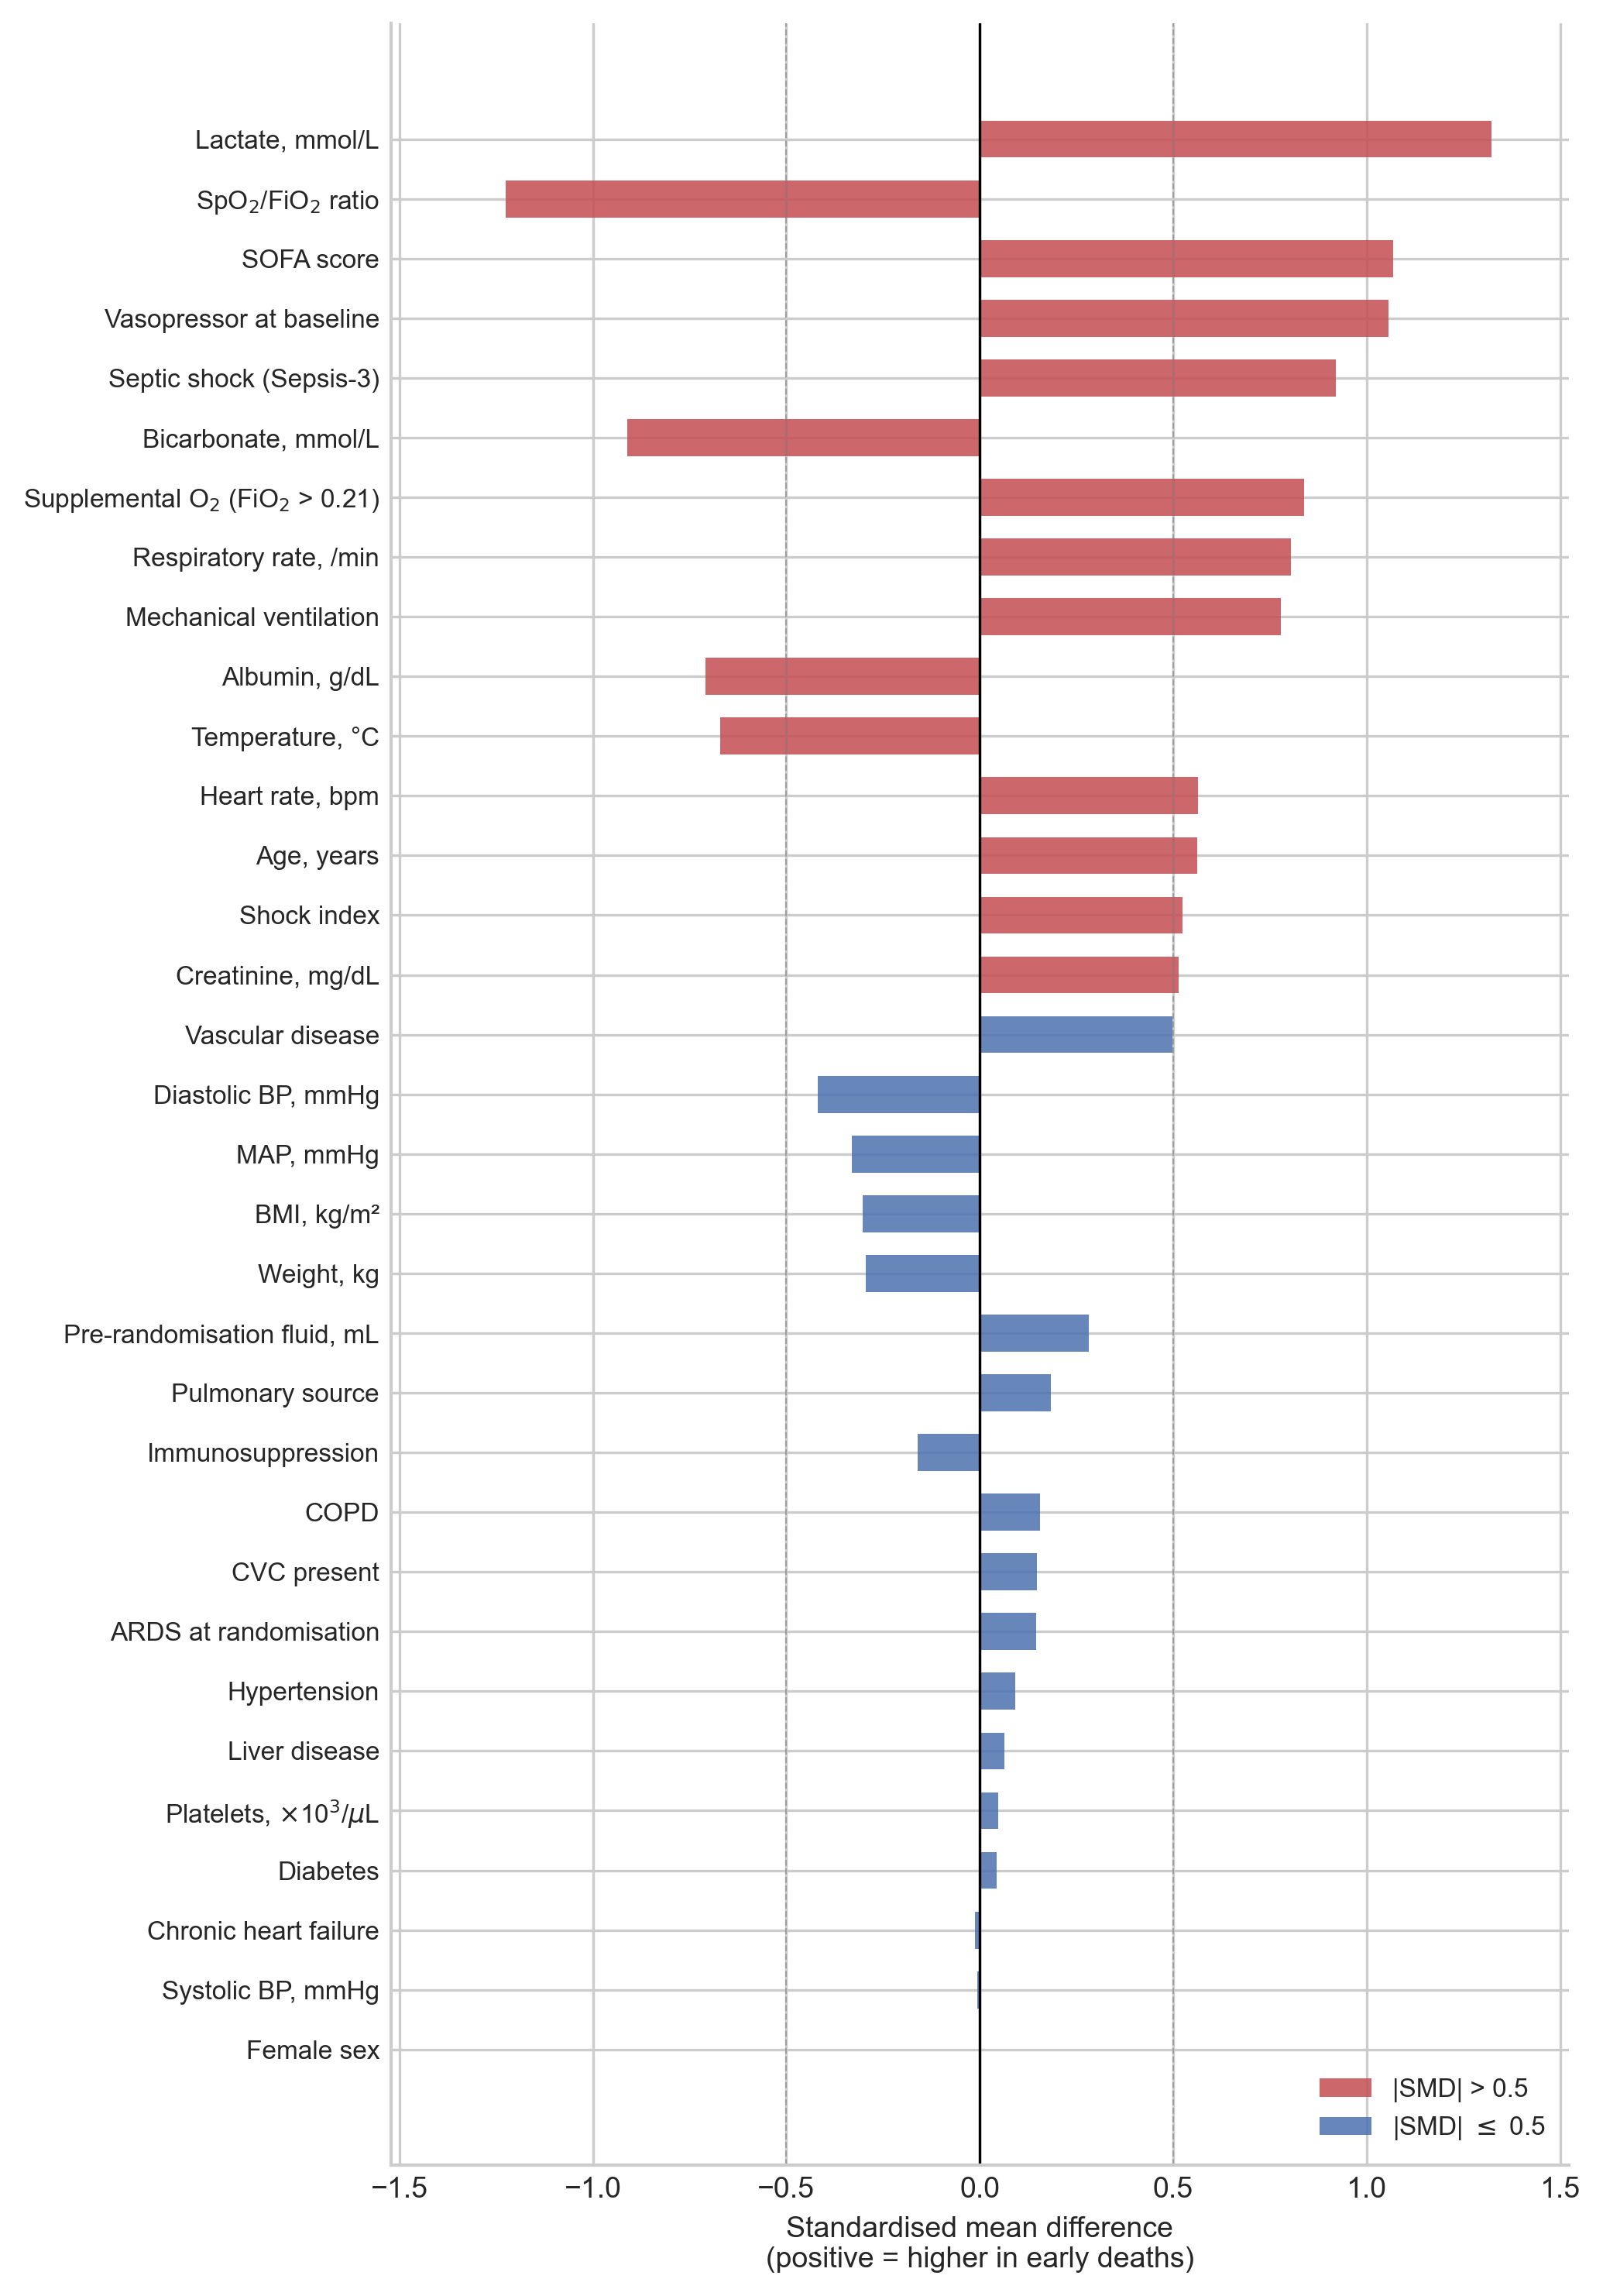

eFigure 3 saved: efigure3_smd_survival24h.pdf / .png / .svg


In [13]:
# eFigure 3: standardised mean differences, 24-hour survivors versus early deaths
# Computed on the individual data of df_hte, not from medians and IQRs.
# Continuous: (mean_dead - mean_alive) / sqrt((sd_alive^2 + sd_dead^2) / 2)
# Binary:     (p_dead - p_alive)       / sqrt(p_bar (1 - p_bar)), p_bar = (p_alive + p_dead) / 2
# Austin P. Stat Med 2009;28:3083-107.
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

matplotlib.rcParams['svg.fonttype'] = 'none'   # keeps text editable in the SVG

alive24 = df_hte[df_hte['alive_at_24h'] == 1]
dead24 = df_hte[df_hte['alive_at_24h'] == 0]
print(f"24-hour survival: {len(alive24)} alive, {len(dead24)} dead")

# variables shown in the figure, in the order of the display dictionaries
SMD_CONTINUOUS = [
    'age', 'weight_kg', 'bmi', 'temperature_baseline', 'heart_rate_baseline',
    'respiratory_rate_baseline', 'sbp_baseline', 'dbp_baseline', 'map_baseline',
    'shock_index_baseline', 'lactate_baseline', 'creatinine_baseline',
    'platelets_baseline', 'bicarbonate_baseline', 'albumin_baseline',
    'spo2_fio2_ratio_baseline', 'fluid_prerand_total_ml', 'sofa_total_baseline',
]
SMD_BINARY = [
    'female', 'chronic_heart_failure', 'copd', 'diabetes', 'hypertension',
    'liver_disease', 'immunosuppression', 'vascular_disease',
    'sepsis_source_pulmonary', 'septic_shock_baseline', 'on_vasopressor_baseline',
    'cvc_present_baseline', 'on_mech_vent_baseline', 'oxygen_requirement_baseline',
    'ards_at_randomization',
]

# subscripts and superscripts drawn with mathtext: the notebook font has no U+2082 glyph
LABEL_OVERRIDES = {
    'spo2_fio2_ratio_baseline': 'SpO$_2$/FiO$_2$ ratio',
    'oxygen_requirement_baseline': 'Supplemental O$_2$ (FiO$_2$ > 0.21)',
    'spo2_baseline': 'SpO$_2$, %',
    'fio2_baseline': 'FiO$_2$',
    'platelets_baseline': 'Platelets, $\\times$10$^3$/$\\mu$L',
    'sofa_total_baseline': 'SOFA score',
    'on_vasopressor_baseline': 'Vasopressor at baseline',
    'fluid_prerand_total_ml': 'Pre-randomisation fluid, mL',
}

rows = []
for var in SMD_CONTINUOUS:
    if var not in df_hte.columns:
        print(f"  missing column, skipped: {var}")
        continue
    a, b = alive24[var].dropna(), dead24[var].dropna()
    if len(b) < 2:
        continue
    pooled = np.sqrt((a.std(ddof=1) ** 2 + b.std(ddof=1) ** 2) / 2)
    smd = (b.mean() - a.mean()) / pooled if pooled > 0 else 0.0
    rows.append({'variable': var, 'label': CONTINUOUS_DISPLAY[var], 'type': 'continuous',
                 'n_alive': len(a), 'n_dead': len(b),
                 'mean_alive': a.mean(), 'mean_dead': b.mean(),
                 'sd_alive': a.std(ddof=1), 'sd_dead': b.std(ddof=1), 'smd': smd})

for var in SMD_BINARY:
    if var not in df_hte.columns:
        print(f"  missing column, skipped: {var}")
        continue
    a, b = alive24[var].dropna(), dead24[var].dropna()
    if len(b) < 2:
        continue
    p1, p2 = a.mean(), b.mean()
    pbar = (p1 + p2) / 2
    denom = np.sqrt(pbar * (1 - pbar))
    smd = (p2 - p1) / denom if denom > 0 else 0.0
    rows.append({'variable': var, 'label': BINARY_DISPLAY[var], 'type': 'binary',
                 'n_alive': len(a), 'n_dead': len(b),
                 'mean_alive': p1, 'mean_dead': p2,
                 'sd_alive': np.nan, 'sd_dead': np.nan, 'smd': smd})

df_smd = pd.DataFrame(rows).sort_values('smd', key=np.abs, ascending=False).reset_index(drop=True)

# the CSV keeps the plain labels; only the figure uses the mathtext versions
df_smd.to_csv(OUTPUT_DIR / 'efigure3_smd_survival24h.csv', index=False)
print(f"SMD table: {len(df_smd)} variables saved to efigure3_smd_survival24h.csv")
print(df_smd[['label', 'n_dead', 'smd']].to_string(index=False, float_format=lambda x: f"{x:+.3f}"))

plot_labels = [LABEL_OVERRIDES.get(v, lab) for v, lab in zip(df_smd['variable'], df_smd['label'])]

# Figure
fig, ax = plt.subplots(figsize=(7, 0.26 * len(df_smd) + 1.4))
y = np.arange(len(df_smd))
colors = ['#c44e52' if abs(s) > 0.5 else '#4c72b0' for s in df_smd['smd']]

ax.barh(y, df_smd['smd'], height=0.62, color=colors, edgecolor='none', alpha=0.85)
ax.axvline(0, color='black', lw=0.8)
for v in (-0.5, 0.5):
    ax.axvline(v, color='grey', lw=0.5, ls='--', alpha=0.6)

ax.set_yticks(y)
ax.set_yticklabels(plot_labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel('Standardised mean difference\n(positive = higher in early deaths)', fontsize=9)
# no title: the caption lives in the supplement, not in the graphic

ax.legend(handles=[Patch(facecolor='#c44e52', alpha=0.85, label='|SMD| > 0.5'),
                   Patch(facecolor='#4c72b0', alpha=0.85, label='|SMD| $\\leq$ 0.5')],
          loc='lower right', fontsize=8, framealpha=0.9)

span = float(np.abs(df_smd['smd']).max()) + 0.2
ax.set_xlim(-span, span)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
for ext in ('pdf', 'png', 'svg'):
    fig.savefig(OUTPUT_DIR / f'efigure3_smd_survival24h.{ext}', dpi=600, bbox_inches='tight')
plt.show()
print("eFigure 3 saved: efigure3_smd_survival24h.pdf / .png / .svg")

## 6. Multiple imputation

Twenty datasets imputed by chained equations (Bayesian ridge regression with posterior sampling), with treatment and outcome as predictors. Body mass index is recomputed from the imputed weight and height.

In [12]:
# Multiple imputation function

def perform_multiple_imputation_hte(
    df: pd.DataFrame,
    baseline_cols: List[str],
    treatment_col: str,
    outcome_col: str,
    min_max_constraints: Optional[Dict[str, Tuple[float, float]]] = None,
    categorical_cols: Optional[Set[str]] = None,
    M: int = 20,
    max_iter: int = 10,
    random_seed: int = 42,
    verbose: bool = True,
) -> Tuple[List[pd.DataFrame], Dict]:
    """
    Multiple imputation for HTE (Heterogeneous Treatment Effect) analysis.
    
    Automatically detects and handles zero-variance columns (constant values).
    """
    
    # Initialize optional parameters
    min_max_constraints = min_max_constraints or {}
    categorical_cols = categorical_cols or set()
    
    df_orig = df.copy()
    
    # Safety checks
    
    # Check that treatment column exists and is complete
    if treatment_col not in df.columns:
        raise ValueError(f"Treatment column '{treatment_col}' not found in DataFrame")
    
    n_missing_treatment = df[treatment_col].isna().sum()
    if n_missing_treatment > 0:
        raise ValueError(
            f"Treatment variable '{treatment_col}' has {n_missing_treatment} missing values. "
            f"Treatment assignment must be complete for HTE analysis."
        )
    
    # Check that outcome column exists and is complete
    if outcome_col not in df.columns:
        raise ValueError(f"Outcome column '{outcome_col}' not found in DataFrame")
    
    n_missing_outcome = df[outcome_col].isna().sum()
    if n_missing_outcome > 0:
        raise ValueError(
            f"Primary outcome '{outcome_col}' has {n_missing_outcome} missing values. "
            f"Outcome must be complete for HTE analysis. "
            f"Consider complete-case analysis or specialized missing outcome methods."
        )
    
    if verbose:
        print("="*80)
        print("MULTIPLE IMPUTATION FOR HTE ANALYSIS")
        print("="*80)
        print(f"Treatment variable '{treatment_col}' is complete")
        print(f"Primary outcome '{outcome_col}' is complete")
        print(f"\nBaseline covariates to process: {len(baseline_cols)}")
    
    # Check that all baseline columns exist and are numeric
    missing_cols = [col for col in baseline_cols if col not in df.columns]
    if missing_cols:
        raise ValueError(f"Baseline columns not found in DataFrame: {missing_cols}")
    
    non_numeric = []
    for col in baseline_cols:
        try:
            if not (np.issubdtype(df[col].dtype, np.number) or
                    pd.api.types.is_numeric_dtype(df[col])):
                non_numeric.append(col)
        except TypeError:
            # pandas nullable Int64/Float64 - numeric but np.issubdtype can't parse them
            if not pd.api.types.is_numeric_dtype(df[col]):
                non_numeric.append(col)
    
    if non_numeric:
        raise TypeError(
            f"All baseline columns must be numeric. Non-numeric columns: {non_numeric}"
        )
    
    # Detect zero-variance columns
    
    # Variables used as predictors: baseline + treatment + outcome
    all_predictor_cols = list(dict.fromkeys(baseline_cols + [treatment_col, outcome_col]))
    
    # Check for zero-variance columns
    zero_variance_cols = []
    for col in all_predictor_cols:
        obs = df[col].dropna()
        if len(obs) > 0:
            variance = obs.var()
            unique_vals = obs.nunique()
            if variance == 0 or unique_vals == 1:
                zero_variance_cols.append(col)
    
    if zero_variance_cols and verbose:
        print(f"\nWARNING: Detected {len(zero_variance_cols)} zero-variance columns (constant values):")
        for col in zero_variance_cols:
            const_val = df[col].dropna().iloc[0]
            print(f"  - {col:45s}: constant value = {const_val}")
        print("  -> These will be excluded from imputation model but preserved in output")
    
    # Separate columns to impute into those with variance and zero-variance
    baseline_with_variance = [col for col in baseline_cols if col not in zero_variance_cols]
    baseline_zero_variance = [col for col in baseline_cols if col in zero_variance_cols]
    
    # Only include non-zero-variance columns in imputation model
    cols_for_model = [col for col in all_predictor_cols if col not in zero_variance_cols]
    
    if verbose and baseline_zero_variance:
        print(f"\nImputation will use {len(cols_for_model)} variables (excluded {len(zero_variance_cols)} constants)")
    
    # Identify missing values
    
    miss_counts = df[baseline_with_variance].isnull().sum()
    cols_with_missing = miss_counts[miss_counts > 0].index.tolist()
    
    if not cols_with_missing:
        if verbose:
            print("\nNo missing values in baseline covariates.")
            print("  Returning original DataFrame (no imputation needed).")
        return [df_orig], {
            "M": 1,
            "baseline_columns": baseline_cols,
            "treatment_column": treatment_col,
            "outcome_column": outcome_col,
            "columns_with_missing": [],
            "missing_counts": {},
            "categorical_columns": list(categorical_cols),
            "zero_variance_columns": baseline_zero_variance,
        }
    
    if verbose:
        print(f"\nColumns with missing values ({len(cols_with_missing)}):")
        for col in cols_with_missing:
            n_miss = miss_counts[col]
            pct_miss = (n_miss / len(df)) * 100
            print(f"  - {col:45s}: {n_miss:4d} missing ({pct_miss:5.1f}%)")
    
    # Set up the imputation model
    
    if verbose:
        print(f"\nImputation model configuration:")
        print(f"  Variables to impute: {len(baseline_with_variance)} (baseline covariates with variance)")
        print(f"  Predictors in model: {len(cols_for_model)} (baseline + treatment + outcome, excluding constants)")
        print(f"  -> Using treatment and outcome as predictors improves efficiency")
    
    # Set up min/max constraints for imputation
    min_values = []
    max_values = []
    
    for col in cols_for_model:
        if col in min_max_constraints:
            mn, mx = min_max_constraints[col]
            if verbose and col in cols_with_missing:
                print(f"    User-specified bounds for '{col}': [{mn:.2f}, {mx:.2f}]")
        else:
            # Auto-detect from observed values
            obs = df[col].dropna()
            if obs.empty:
                raise ValueError(
                    f"Column '{col}' is entirely missing. "
                    f"Please provide min_max_constraints for this column."
                )
            mn, mx = float(obs.min()), float(obs.max())
            
            # Add small buffer to avoid edge issues (0.1% of range)
            range_val = mx - mn
            if range_val > 0:
                buffer = range_val * 0.001
                mn -= buffer
                mx += buffer
        
        min_values.append(mn)
        max_values.append(mx)
    
    # Perform multiple imputation
    
    X_for_imputation = df[cols_for_model].copy()
    imputed_datasets = []
    
    # Generate independent random seeds for each imputation
    seed_seq = np.random.SeedSequence(random_seed)
    child_seeds = seed_seq.spawn(M)
    
    if verbose:
        print(f"\n{'='*80}")
        print(f"Generating {M} imputed datasets...")
        print(f"{'='*80}")
    
    for m in range(M):
        if verbose and ((m + 1) % 5 == 0 or m == 0):
            print(f"  Progress: {m + 1:2d}/{M} datasets completed", end='\r')
        
        # Get integer seed for sklearn
        seed_int = int(child_seeds[m].generate_state(1, dtype=np.uint32)[0])
        
        # Create and fit imputer
        imputer = IterativeImputer(
            max_iter=max_iter,
            random_state=seed_int,
            sample_posterior=True,
            min_value=np.array(min_values),
            max_value=np.array(max_values),
        )
        
        # Perform imputation on all predictor variables
        X_imputed = imputer.fit_transform(X_for_imputation)
        df_imputed = pd.DataFrame(
            X_imputed, 
            columns=cols_for_model, 
            index=X_for_imputation.index
        )
        
        # Handle categorical columns (round to nearest integer)
        for col in categorical_cols:
            if col in cols_with_missing:
                mask_na = df[col].isna()
                if mask_na.any():
                    df_imputed.loc[mask_na, col] = np.round(df_imputed.loc[mask_na, col])
                    # Ensure binary variables stay 0/1
                    if set(df[col].dropna().unique()).issubset({0, 1}):
                        df_imputed.loc[mask_na, col] = df_imputed.loc[mask_na, col].clip(0, 1)
        
        # Create complete dataset by updating only the missing values
        df_complete = df_orig.copy()
        
        for col in cols_with_missing:
            mask_na = df[col].isna()
            if mask_na.any():
                df_complete.loc[mask_na, col] = df_imputed.loc[mask_na, col]
        
        # Zero-variance columns are already complete (by definition), just preserve them
        
        imputed_datasets.append(df_complete)
    
    if verbose:
        print(f"  Progress: {M:2d}/{M} datasets completed")
        print(f"\nMultiple imputation complete.")
        print(f"  Generated {M} datasets with complete baseline covariates")
    
    # Return results
    
    info = {
        "M": M,
        "baseline_columns": baseline_cols,
        "treatment_column": treatment_col,
        "outcome_column": outcome_col,
        "columns_with_missing": cols_with_missing,
        "missing_counts": miss_counts[cols_with_missing].to_dict(),
        "categorical_columns": list(categorical_cols),
        "zero_variance_columns": baseline_zero_variance,
        "max_iter": max_iter,
        "random_seed": random_seed,
    }
    
    return imputed_datasets, info


In [13]:
# Run the multiple imputation, once per outcome (the outcome is a predictor)
# Clinical bounds for the imputed values, in place of the observed minimum and maximum.
CLINICAL_BOUNDS = {
    'weight_kg':          (30.0,   250.0),
    'height_cm':          (130.0,  210.0),
    'wbc_baseline':       (100.0,  80000.0),
    'platelets_baseline': (5.0,    1500.0),
    'bilirubin_baseline': (0.1,    50.0),
    'lactate_baseline':   (0.2,    25.0),
    'creatinine_baseline':(0.1,    15.0),
    'glucose_baseline':   (20.0,   800.0),
    'bun_baseline':       (2.0,    200.0),
    'sodium_baseline':    (110.0,  170.0),
    'potassium_baseline': (2.0,    8.0),
    'chloride_baseline':  (70.0,   135.0),
    'bicarbonate_baseline':(4.0,   45.0),
    'albumin_baseline':   (0.5,    6.0),
    'hematocrit_baseline':(10.0,   65.0),
    'heart_rate_baseline':(20.0,   220.0),
    'respiratory_rate_baseline':(4.0, 60.0),
    'temperature_baseline':(32.0,  42.0),
    'sbp_baseline':       (30.0,   260.0),
    'dbp_baseline':       (15.0,   160.0),
    'map_baseline':       (20.0,   200.0),
    'shock_index_baseline':(0.2,   3.5),
    'spo2_baseline':      (50.0,   100.0),
    'fio2_baseline':      (0.21,   1.0),
    'spo2_fio2_ratio_baseline':(50.0, 500.0),
}

# Impute for primary outcome
print("Imputing for PRIMARY outcome:", PRIMARY_OUTCOME)
imputed_datasets_primary, mi_info_primary = perform_multiple_imputation_hte(
    df_hte[df_hte[PRIMARY_OUTCOME].notna()].copy(),
    all_covariates, TREATMENT_VAR, PRIMARY_OUTCOME,
    min_max_constraints=CLINICAL_BOUNDS,
    categorical_cols=set(binary_baseline + sofa_baseline),
    M=N_IMPUTATIONS, random_seed=SEED
)

# Impute for the secondary outcome (90-day mortality)
print("\nImputing for SECONDARY outcome:", SECONDARY_OUTCOME)
imputed_datasets_secondary, mi_info_secondary = perform_multiple_imputation_hte(
    df_hte[df_hte[SECONDARY_OUTCOME].notna()].copy(),
    all_covariates, TREATMENT_VAR, SECONDARY_OUTCOME,
    min_max_constraints=CLINICAL_BOUNDS,
    categorical_cols=set(binary_baseline + sofa_baseline),
    M=N_IMPUTATIONS, random_seed=SEED
)

print(f"\nPrimary MI:    {len(imputed_datasets_primary)} datasets, n={len(imputed_datasets_primary[0])}")
print(f"Secondary MI:  {len(imputed_datasets_secondary)} datasets, n={len(imputed_datasets_secondary[0])}")

Imputing for PRIMARY outcome: alive_discharged_28d
MULTIPLE IMPUTATION FOR HTE ANALYSIS
Treatment variable 'restrictive_fluid' is complete
Primary outcome 'alive_discharged_28d' is complete

Baseline covariates to process: 57

Columns with missing values (29):
  - weight_kg                                    :    9 missing (  0.6%)
  - height_cm                                    :   41 missing (  2.7%)
  - temperature_baseline                         :   51 missing (  3.3%)
  - heart_rate_baseline                          :    5 missing (  0.3%)
  - respiratory_rate_baseline                    :   11 missing (  0.7%)
  - dbp_baseline                                 :    7 missing (  0.5%)
  - map_baseline                                 :    7 missing (  0.5%)
  - shock_index_baseline                         :    5 missing (  0.3%)
  - lactate_baseline                             :  170 missing ( 11.0%)
  - bilirubin_baseline                           :  226 missing ( 14.7%)
  - creat

In [14]:
# BMI is computed from the imputed weight and height in each dataset
for ds_list in (imputed_datasets_primary, imputed_datasets_secondary):
    for imp in ds_list:
        imp['bmi'] = imp['weight_kg'] / ((imp['height_cm'] / 100) ** 2)
        # Plausibility clip (same bounds as before imputation)
        imp.loc[(imp['bmi'] < 10) | (imp['bmi'] > 80), 'bmi'] = np.nan

bmi_check = imputed_datasets_primary[0]['bmi']
print(f"Post-imputation BMI (dataset 0): n={bmi_check.notna().sum()}, "
      f"median={bmi_check.median():.2f}, mean={bmi_check.mean():.2f}")

Post-imputation BMI (dataset 0): n=1540, median=25.84, mean=27.21


## 7. Subgroup interactions

Three subgroups chosen for biological plausibility: septic shock at baseline (vasopressor infusion with lactate above 2 mmol/L, the dataset having no septic-shock field), pre-existing renal impairment (chronic kidney disease or chronic dialysis) and ARDS at randomisation. Logistic regression with a treatment-by-subgroup interaction, and Holm correction across the three tests of each outcome (Table E2).

In [15]:
# Subgroup interactions
print("="*70)
print("SUBGROUP INTERACTIONS")
print("="*70)

SUBGROUPS = {
    'Septic shock': ('septic_shock_baseline', 'binary'),
    'Renal impairment': ('renal_status', 'ordinal'),  # 0 vs 1-2
    'ARDS at randomization': ('ards_at_randomization', 'binary'),
}

def test_subgroup_interaction(df, outcome, treatment, subgroup_var, var_type='binary'):
    """Test treatment x subgroup interaction via logistic regression."""
    d = df[[treatment, outcome, subgroup_var]].dropna().copy()
    if var_type == 'ordinal':
        d['subgroup_bin'] = (d[subgroup_var] >= 1).astype(int)
    else:
        d['subgroup_bin'] = d[subgroup_var].astype(int)
    
    formula = f"{outcome} ~ {treatment} * subgroup_bin"
    try:
        fit = smf.logit(formula, data=d).fit(disp=0)
        interaction_term = f"{treatment}:subgroup_bin"
        if interaction_term in fit.params:
            return {
                'coef': fit.params[interaction_term],
                'se': fit.bse[interaction_term],
                'p': fit.pvalues[interaction_term],
                'n0': (d['subgroup_bin']==0).sum(),
                'n1': (d['subgroup_bin']==1).sum(),
            }
    except:
        pass
    return {'coef': np.nan, 'se': np.nan, 'p': np.nan, 'n0': np.nan, 'n1': np.nan}

for outcome_label, outcome_var in [('PRIMARY (28d discharge)', PRIMARY_OUTCOME),
                                     ('SECONDARY (90d mortality)', SECONDARY_OUTCOME)]:
    print(f"\n--- {outcome_label} ---")
    results_subgroup = []
    for sg_name, (sg_var, sg_type) in SUBGROUPS.items():
        if sg_var not in df_hte.columns:
            print(f"  {sg_name}: variable {sg_var} not found - SKIPPING")
            continue
        res = test_subgroup_interaction(df_hte, outcome_var, TREATMENT_VAR, sg_var, sg_type)
        results_subgroup.append({'Subgroup': sg_name, **res})
        print(f"  {sg_name:30s}: coef={res['coef']:+.3f}  p={res['p']:.3f}  (n={res['n0']:.0f}/{res['n1']:.0f})")
    
    # Holm correction
    pvals = [r['p'] for r in results_subgroup if not np.isnan(r['p'])]
    if pvals:
        reject, p_adj, _, _ = multipletests(pvals, method='holm')
        print(f"  Holm-adjusted p-values: {[f'{p:.3f}' for p in p_adj]}")
        print(f"  Any significant after Holm: {any(reject)}")


SUBGROUP INTERACTIONS

--- PRIMARY (28d discharge) ---
  Septic shock                  : coef=-0.066  p=0.847  (n=1370/170)
  Renal impairment              : coef=+0.452  p=0.199  (n=1368/172)
  ARDS at randomization         : coef=-0.250  p=0.693  (n=1498/42)
  Holm-adjusted p-values: ['1.000', '0.598', '1.000']
  Any significant after Holm: False

--- SECONDARY (90d mortality) ---
  Septic shock                  : coef=-0.086  p=0.800  (n=1370/170)
  Renal impairment              : coef=-0.705  p=0.042  (n=1368/172)
  ARDS at randomization         : coef=+0.378  p=0.553  (n=1498/42)
  Holm-adjusted p-values: ['1.000', '0.125', '1.000']
  Any significant after Holm: False


## 8. Fisher randomisation test

Null hypothesis of a constant effect, Y(1) = Y(0) + tau for every patient, tested by comparing the variances of the two arms after subtracting tau in the restrictive arm (Ding, Feller and Miratrix 2016). tau is swept over 51 values spanning the 99.9% confidence interval of the average effect, with 10,000 permutations stratified by randomisation location, unadjusted and adjusted for the 57 baseline variables. The median p-value over the 20 imputed datasets is reported (eFigure 2). With a binary outcome a constant shift cannot hold near 0 and 1, so the test detects variation only when it changes the spread of outcomes, and non-rejection is conservative (Methods E2).

In [16]:
# Helper functions for the Fisher randomisation test
import statsmodels.api as sm

def stratified_permutation(z, strata, rng=None):
    """Permute treatment within each stratum (randomisation location)."""
    if rng is None:
        rng = np.random.default_rng()
    z_perm = np.zeros_like(z)
    for s in np.unique(strata):
        idx = (strata == s)
        z_perm[idx] = rng.permutation(z[idx])
    return z_perm

def variance_ratio(y_adj, z):
    """Variance ratio |log(var1/var0)| (Ding et al. Sec 3.1).
    
    Uniformly most powerful for detecting HTE under normality (Cox 1984).
    Under H0: Yi(1) = Yi(0) + tau, Var(Y(1)) = Var(Y(0)).
    """
    v0 = np.var(y_adj[z == 0], ddof=1)
    v1 = np.var(y_adj[z == 1], ddof=1)
    if v0 == 0 or v1 == 0:
        return 0.0
    return abs(np.log(v1 / v0))

def frt_ci_sweep(y, z, strata, tau_grid, statistic_func, n_perm=10000,
                 seed=42, gamma=0.001):
    """
    FRT-CI sweep (Ding et al. Sec 4.2.2; Berger & Boos 1994).
    For each tau in grid: impute science table, permutation test.
    Sweep p-value = max(pointwise p-values) + gamma.
    """
    rng = np.random.default_rng(seed)
    pvals = []

    for tau in tqdm(tau_grid, desc="FRT-CI Sweep"):
        y_adj = y - z * tau
        t_obs = statistic_func(y_adj, z)

        t_null = np.empty(n_perm)
        for b in range(n_perm):
            z_perm = stratified_permutation(z, strata, rng)
            t_null[b] = statistic_func(y_adj, z_perm)

        p = (np.sum(t_null >= t_obs) + 1) / (n_perm + 1)
        pvals.append(p)

    max_pw = float(max(pvals))
    sweep_p = float(min(max_pw + gamma, 1.0))

    return {
        "tau_grid": tau_grid,
        "pointwise_pvalues": np.array(pvals),
        "sweep_pvalue": sweep_p,
        "max_pointwise": max_pw,
        "gamma": gamma,
    }

def frt_ci_sweep_adjusted(y, z, X, strata, tau_grid, statistic_func,
                           n_perm=10000, seed=42, gamma=0.001):
    """
    Covariate-adjusted FRT-CI sweep (Ding et al. Sec 5.1).
    For each tau: (1) adjust y_adj = y - z*tau, (2) regress y_adj on X
    to get residuals, (3) run FRT on residuals.
    Validity guaranteed by randomisation alone (Lin 2013).
    """
    rng = np.random.default_rng(seed)
    pvals = []
    X_c = sm.add_constant(X, has_constant=False)

    for tau in tqdm(tau_grid, desc="Adjusted FRT-CI Sweep"):
        y_adj = y - z * tau
        resid = sm.OLS(y_adj, X_c, missing='none').fit().resid

        t_obs = statistic_func(resid, z)

        t_null = np.empty(n_perm)
        for b in range(n_perm):
            z_perm = stratified_permutation(z, strata, rng)
            t_null[b] = statistic_func(resid, z_perm)

        p = (np.sum(t_null >= t_obs) + 1) / (n_perm + 1)
        pvals.append(p)

    max_pw = float(max(pvals))
    sweep_p = float(min(max_pw + gamma, 1.0))

    return {
        "tau_grid": tau_grid,
        "pointwise_pvalues": np.array(pvals),
        "sweep_pvalue": sweep_p,
        "max_pointwise": max_pw,
        "gamma": gamma,
    }


In [17]:
# Fisher randomisation test on the primary outcome, over the imputed datasets
# Loops the Fisher randomisation test across all M=20 imputed datasets and
# reports the median sweep p-value across imputations (Methods E2 / Pooling
# rules in Additional file 1). For the unadjusted variant, treatment and
# outcome are complete, so per-imputation results differ only via Monte Carlo
# noise; for the covariate-adjusted variant, residualisation depends on the
# imputed covariate values, so across-imputation variability is meaningful.

import time

# Treatment / strata are common across imputations (both complete)
df0 = imputed_datasets_primary[0]
z_raw_global = df0[TREATMENT_VAR].values
z_global, z_uniques = pd.factorize(z_raw_global, sort=True)
print("Treatment encoding:", {code: name for code, name in enumerate(z_uniques)})

# Permutations within the randomisation-location strata (section 2)
strata_global = loc_strata.reindex(df0.index).fillna('unknown').astype(str).values
print(f"Permutation strata: {len(np.unique(strata_global))}")

y_global = df0[PRIMARY_OUTCOME].values.astype(float)
mask_global = ~np.isnan(y_global)
y_global = y_global[mask_global]
z_global = z_global[mask_global]
strata_global = strata_global[mask_global]

# Outcome and treatment are complete in this analysis cohort, so the
# unadjusted ATE / SE / grid are identical across imputations.
ate_global = float(np.mean(y_global[z_global == 1]) - np.mean(y_global[z_global == 0]))
se_global = float(np.sqrt(
    np.var(y_global[z_global == 1], ddof=1) / np.sum(z_global == 1) +
    np.var(y_global[z_global == 0], ddof=1) / np.sum(z_global == 0)
))
Z_CRIT = norm.ppf(0.9995)  # 3.29
GAMMA = 0.001
N_PERM_FRT = 10000
tau_grid_global = np.linspace(
    ate_global - Z_CRIT * se_global,
    ate_global + Z_CRIT * se_global,
    51
)

print(f"\n{PRIMARY_OUTCOME}: ATE = {ate_global:.4f}, SE = {se_global:.4f}")
print(f"Tau grid: [{tau_grid_global[0]:.4f}, {tau_grid_global[-1]:.4f}], "
      f"{len(tau_grid_global)} points")
print(f"Permutations per grid point: {N_PERM_FRT:,}")
print(f"Imputations to loop: {len(imputed_datasets_primary)}")

# Covariates of the adjusted variant: the 57 baseline variables (the imputed data are complete)
adj_cols = [c for c in all_covariates
            if c in df0.columns and df0[c].isna().mean() < 0.10]
print(f"Adjustment covariates (missingness <10%): {len(adj_cols)}")

# Loop over imputations
unadj_results = []   # one dict per imputation
adj_results = []     # one dict per imputation

t_start = time.time()
for m, df_m in enumerate(imputed_datasets_primary):
    # Build adjustment matrix for this imputation (covariate values may differ)
    X_parts = []
    for c in adj_cols:
        col = pd.to_numeric(df_m.loc[mask_global, c], errors='coerce').values.astype(float)
        # Imputed values should be complete; nan-safe fallback just in case
        col = np.where(np.isnan(col), np.nanmedian(col), col)
        X_parts.append(col.reshape(-1, 1))
    X_m = np.hstack(X_parts) if X_parts else np.ones((mask_global.sum(), 1))

    # Unadjusted test
    res_unadj = frt_ci_sweep(
        y_global, z_global, strata_global, tau_grid_global,
        variance_ratio, n_perm=N_PERM_FRT, gamma=GAMMA, seed=100 + m
    )

    # Covariate-adjusted test
    res_adj = frt_ci_sweep_adjusted(
        y_global, z_global, X_m, strata_global, tau_grid_global,
        variance_ratio, n_perm=N_PERM_FRT, gamma=GAMMA, seed=200 + m
    )

    unadj_results.append(res_unadj)
    adj_results.append(res_adj)

    elapsed = time.time() - t_start
    print(f"  Imputation {m + 1:2d}/{len(imputed_datasets_primary)}: "
          f"unadj sweep p = {res_unadj['sweep_pvalue']:.4f}, "
          f"adj sweep p = {res_adj['sweep_pvalue']:.4f} "
          f"(elapsed {elapsed:6.1f}s)")

# Pool across imputations
def _pool(res_list, label):
    sweep_ps = np.array([r['sweep_pvalue'] for r in res_list])
    max_pws = np.array([r['max_pointwise'] for r in res_list])
    pointwise_matrix = np.array([r['pointwise_pvalues'] for r in res_list])  # M x G

    median_p = float(np.median(sweep_ps))
    q25, q75 = float(np.quantile(sweep_ps, 0.25)), float(np.quantile(sweep_ps, 0.75))
    pmin, pmax = float(sweep_ps.min()), float(sweep_ps.max())

    print(f"\n{'=' * 60}")
    print(f"{label}: pooled across {len(res_list)} imputations")
    print(f"{'=' * 60}")
    print(f"  Median sweep p:  {median_p:.4f}")
    print(f"  IQR:             [{q25:.4f}, {q75:.4f}]")
    print(f"  Range:           [{pmin:.4f}, {pmax:.4f}]")
    print(f"  N below 0.05:    {int((sweep_ps < 0.05).sum())}/{len(sweep_ps)}")

    return {
        'sweep_ps': sweep_ps,
        'max_pws': max_pws,
        'pointwise_matrix': pointwise_matrix,
        'tau_grid': res_list[0]['tau_grid'],
        'median_sweep_p': median_p,
        'iqr_lo': q25,
        'iqr_hi': q75,
        'range_lo': pmin,
        'range_hi': pmax,
        'n_imputations': len(res_list),
    }

print("\n" + "=" * 60)
print("POOLED FRT RESULTS - MEDIAN SWEEP P-VALUE ACROSS IMPUTATIONS")
print("=" * 60)
unadj_pool = _pool(unadj_results, "A. UNADJUSTED variance ratio")
adj_pool = _pool(adj_results, "B. COVARIATE-ADJUSTED variance ratio")

# Results used by the export cell (section 12)
unadj_pool['sweep_pvalue'] = unadj_pool['median_sweep_p']
unadj_pool['max_pointwise'] = float(np.median(unadj_pool['max_pws']))
adj_pool['sweep_pvalue'] = adj_pool['median_sweep_p']
adj_pool['max_pointwise'] = float(np.median(adj_pool['max_pws']))

frt_primary = {
    'unadjusted': unadj_pool,
    'adjusted': adj_pool,
    'ate': ate_global,
    'se': se_global,
    'n_imputations': len(imputed_datasets_primary),
    'n_perm': N_PERM_FRT,
    'tau_grid': tau_grid_global,
}

# eFigure 2: median pointwise p-value with the interquartile band across imputations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

panels = [
    (axes[0], unadj_pool, "Unadjusted"),
    (axes[1], adj_pool, "Covariate-adjusted"),
]

for ax, pool, title in panels:
    pw = pool['pointwise_matrix']           # M x G
    median_pw = np.median(pw, axis=0)
    q25_pw = np.quantile(pw, 0.25, axis=0)
    q75_pw = np.quantile(pw, 0.75, axis=0)
    grid = pool['tau_grid']

    ax.fill_between(grid, q25_pw, q75_pw, color='steelblue', alpha=0.25,
                    label='25%-75% IQR across imputations')
    ax.plot(grid, median_pw, 'o-', markersize=3, lw=1.4, color='steelblue',
            label='Median across imputations')
    ax.axhline(0.05, ls='--', color='red', alpha=0.6, label='alpha = 0.05')
    ax.axvline(ate_global, ls=':', color='gray', alpha=0.6,
               label=f'ATE = {ate_global:.4f}')
    ax.set_xlabel('Candidate constant treatment effect (tau)')
    ax.set_ylabel('Pointwise p-value')
    ax.set_title(f"{title}\n"
                 f"median sweep p = {pool['median_sweep_p']:.3f} "
                 f"[IQR {pool['iqr_lo']:.3f}-{pool['iqr_hi']:.3f}]")
    ax.legend(fontsize=8, loc='lower center')
    ax.set_ylim(-0.02, 1.02)

fig.suptitle(
    f'FRT-CI Sweep: Alive-discharged day 28 '
    f'(M={len(imputed_datasets_primary)} imputations)',
    fontsize=11, fontweight='bold'
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'efigure_frt_sweep.pdf', dpi=300, bbox_inches='tight')
fig.savefig(OUTPUT_DIR / 'efigure_frt_sweep.png', dpi=300, bbox_inches='tight')
plt.show()

# Per-imputation sweep p-values
sweep_log = pd.DataFrame({
    'imputation': np.arange(1, len(imputed_datasets_primary) + 1),
    'unadj_sweep_p': unadj_pool['sweep_ps'],
    'unadj_max_pw': unadj_pool['max_pws'],
    'adj_sweep_p': adj_pool['sweep_ps'],
    'adj_max_pw': adj_pool['max_pws'],
})
sweep_log.to_csv(OUTPUT_DIR / 'frt_sweep_per_imputation.csv', index=False)
print(f"\nPer-imputation sweep p-values saved: frt_sweep_per_imputation.csv")


Treatment encoding: {0: np.int64(0), 1: np.int64(1)}
Permutation strata: 5

alive_discharged_28d: ATE = 0.0052, SE = 0.0202
Tau grid: [-0.0614, 0.0718], 51 points
Permutations per grid point: 10,000
Imputations to loop: 20
Adjustment covariates (missingness <10%): 57


  Imputation  1/20: unadj sweep p = 0.8135, adj sweep p = 0.5761 (elapsed  419.7s)


  Imputation  2/20: unadj sweep p = 0.8084, adj sweep p = 0.6544 (elapsed  835.1s)


  Imputation  3/20: unadj sweep p = 0.8109, adj sweep p = 0.7130 (elapsed 1256.1s)


  Imputation  4/20: unadj sweep p = 0.8111, adj sweep p = 0.4808 (elapsed 1674.7s)


  Imputation  5/20: unadj sweep p = 0.8094, adj sweep p = 0.5841 (elapsed 2096.2s)


... (12 outputs left out)

  Imputation 18/20: unadj sweep p = 0.8079, adj sweep p = 0.8151 (elapsed 7767.5s)


  Imputation 19/20: unadj sweep p = 0.8115, adj sweep p = 0.4316 (elapsed 8206.8s)


  Imputation 20/20: unadj sweep p = 0.8108, adj sweep p = 0.8328 (elapsed 8645.8s)

POOLED FRT RESULTS - MEDIAN SWEEP P-VALUE ACROSS IMPUTATIONS

A. UNADJUSTED variance ratio: pooled across 20 imputations
  Median sweep p:  0.8109
  IQR:             [0.8098, 0.8114]
  Range:           [0.8079, 0.8135]
  N below 0.05:    0/20

B. COVARIATE-ADJUSTED variance ratio: pooled across 20 imputations
  Median sweep p:  0.6427
  IQR:             [0.5738, 0.7855]
  Range:           [0.4316, 0.8413]
  N below 0.05:    0/20



Per-imputation sweep p-values saved: frt_sweep_per_imputation.csv


## 9. Power of the randomisation test

Simulated trials the size of CLOVERS under two forms of heterogeneity: an extra benefit confined to a subgroup the size of the septic-shock subgroup, and individual effects spread around the average effect. Power is computed at the true average effect and is therefore an upper bound (Table E4).

In [18]:
# Power of the Fisher randomisation test (Table E4)
from joblib import Parallel, delayed

# Observed parameters
base_rate = float(np.mean(y_global[z_global == 0]))
# Septic-shock subgroup fraction
shock_frac = df_hte['septic_shock_baseline'].mean()
subgroup_label = 'Septic shock'
n_total = len(y_global)
n_trt = int(np.sum(z_global == 1))
strata_counts = pd.Series(strata_global).value_counts().sort_values().values

print(f"Power of the Fisher randomisation test, simulated binary outcome")
print(f"  N = {n_total}, n_treated = {n_trt}")
print(f"  Baseline outcome rate (control): {base_rate:.3f}")
print(f"  Subgroup ({subgroup_label}): fraction = {shock_frac:.3f}")
print(f"  Randomisation-location strata: {len(strata_counts)}")

N_SIMS = 500
N_PERM_POWER = 1000  # per sim (upper bound: at known ATE)

def simulate_one_frt_binary(n, n1, ate, base_p, hte_delta, pi_affected,
                             scenario, n_perm, strata_sizes, rng_seed):
    """Simulate one dataset with binary outcomes, return 1 if p < 0.05.
    
    'phenotype': affected fraction gets +hte_delta on probability scale
    'spread':    tau_i ~ N(ate, hte_delta^2), applied on probability scale
    """
    rng = np.random.default_rng(rng_seed)

    # Stratified assignment (matching actual trial)
    z = np.zeros(n, dtype=int)
    strata = np.repeat(np.arange(len(strata_sizes)), strata_sizes)
    pos = 0
    for s_size in strata_sizes:
        n_trt_s = max(1, int(round(s_size * n1 / n)))
        n_trt_s = min(n_trt_s, s_size - 1)
        z_s = np.array([1]*n_trt_s + [0]*(s_size - n_trt_s))
        rng.shuffle(z_s)
        z[pos:pos+s_size] = z_s
        pos += s_size

    # Individual treatment effects
    if scenario == 'phenotype':
        is_affected = np.zeros(n, dtype=bool)
        n_affected = int(round(n * pi_affected))
        is_affected[rng.choice(n, n_affected, replace=False)] = True
        tau = np.where(is_affected, ate + hte_delta, ate)
    elif scenario == 'spread':
        tau = rng.normal(ate, hte_delta, size=n)

    # Generate binary outcomes
    p_i = np.clip(base_p + z * tau, 0.01, 0.99)
    y = rng.binomial(1, p_i).astype(float)

    # FRT at known ATE (upper bound on FRT-CI power)
    y_adj = y - z * ate
    t_obs = variance_ratio(y_adj, z)

    t_null = np.empty(n_perm)
    for b_idx in range(n_perm):
        z_p = stratified_permutation(z, strata, rng)
        t_null[b_idx] = variance_ratio(y_adj, z_p)

    p = (np.sum(t_null >= t_obs) + 1) / (n_perm + 1)
    return int(p < 0.05)

# Scenario 1: Subgroup-benefit (septic shock)
phenotype_deltas = np.array([0.00, 0.02, 0.05, 0.08, 0.10, 0.15, 0.20])
sigma_tau_implied = phenotype_deltas * np.sqrt(shock_frac * (1 - shock_frac))

print(f"\nScenario 1: Subgroup-benefit ({subgroup_label}, fraction = {shock_frac:.2f})")
print(f"  Delta (extra risk diff):  {phenotype_deltas}")
print(f"  Implied sigma_tau:        {np.round(sigma_tau_implied, 3)}")
print(f"  {N_SIMS} sims x {N_PERM_POWER} perms per sim (upper bound)")

pheno_results = []
for delta in tqdm(phenotype_deltas, desc="Phenotype scenario"):
    rejects = Parallel(n_jobs=-1)(
        delayed(simulate_one_frt_binary)(
            n_total, n_trt, float(ate_global), base_rate,
            float(delta), shock_frac, 'phenotype',
            N_PERM_POWER, strata_counts, seed
        ) for seed in range(N_SIMS)
    )
    power = np.mean(rejects)
    se = np.sqrt(power * (1 - power) / N_SIMS)
    pheno_results.append({
        "delta": delta,
        "sigma_tau": delta * np.sqrt(shock_frac * (1 - shock_frac)),
        "power": power, "se": se
    })

pheno_df = pd.DataFrame(pheno_results)
print("\nPhenotype scenario results:")
print(pheno_df.to_string(index=False, float_format="%.3f"))

# Scenario 2: Continuous spread
spread_sds = np.array([0.00, 0.02, 0.05, 0.08, 0.10, 0.15, 0.20])

print(f"\nScenario 2: Continuous spread")
print(f"  sigma_tau: {spread_sds}")

spread_results = []
for sd in tqdm(spread_sds, desc="Spread scenario"):
    rejects = Parallel(n_jobs=-1)(
        delayed(simulate_one_frt_binary)(
            n_total, n_trt, float(ate_global), base_rate,
            float(sd), 0.0, 'spread',
            N_PERM_POWER, strata_counts, seed
        ) for seed in range(N_SIMS)
    )
    power = np.mean(rejects)
    se = np.sqrt(power * (1 - power) / N_SIMS)
    spread_results.append({"sigma_tau": sd, "power": power, "se": se})

spread_df = pd.DataFrame(spread_results)
print("\nSpread scenario results:")
print(spread_df.to_string(index=False, float_format="%.3f"))

# Store power results
power_df = pd.concat([
    pheno_df.assign(scenario='phenotype'),
    spread_df.assign(scenario='spread')
], ignore_index=True)
power_df.to_csv(OUTPUT_DIR / 'etable_frt_power.csv', index=False)

# Find 80% threshold
above80 = pheno_df[pheno_df['power'] >= 0.80]
if len(above80) > 0:
    print(f"\n80% power reached at delta >= {above80.iloc[0]['delta']:.2f} "
          f"(sigma_tau >= {above80.iloc[0]['sigma_tau']:.3f})")
else:
    print(f"\n80% power NOT reached in tested range (max power = {pheno_df['power'].max():.2f})")

Power of the Fisher randomisation test, simulated binary outcome
  N = 1540, n_treated = 770
  Baseline outcome rate (control): 0.801
  Subgroup (Septic shock): fraction = 0.110
  Randomisation-location strata: 5

Scenario 1: Subgroup-benefit (Septic shock, fraction = 0.11)
  Delta (extra risk diff):  [0.   0.02 0.05 0.08 0.1  0.15 0.2 ]
  Implied sigma_tau:        [0.    0.006 0.016 0.025 0.031 0.047 0.063]
  500 sims x 1000 perms per sim (upper bound)



Phenotype scenario results:
 delta  sigma_tau  power    se
 0.000      0.000  0.044 0.009
 0.020      0.006  0.044 0.009
 0.050      0.016  0.058 0.010
 0.080      0.025  0.080 0.012
 0.100      0.031  0.098 0.013
 0.150      0.047  0.150 0.016
 0.200      0.063  0.210 0.018

Scenario 2: Continuous spread
  sigma_tau: [0.   0.02 0.05 0.08 0.1  0.15 0.2 ]



Spread scenario results:
 sigma_tau  power    se
     0.000  0.062 0.011
     0.020  0.064 0.011
     0.050  0.056 0.010
     0.080  0.062 0.011
     0.100  0.068 0.011
     0.150  0.040 0.009
     0.200  0.108 0.014



80% power NOT reached in tested range (max power = 0.21)


## 10. BART

Individual predicted effects from Bayesian additive regression trees (R package bartCause). Five-fold cross-fitting gives each patient a prediction from a model not trained on that patient. The calibration test regresses the outcome on treatment, the prediction and their product. The machine-learning analyses use the 20th imputed dataset.

In [19]:
# BART S-learner with the R package bartCause, five-fold cross-fitting
RSCRIPT_PATH = shutil.which('Rscript')
print(f"R found at: {RSCRIPT_PATH}")

# R BART with five-fold cross-fitting
def r_bart_crossfit(df_in, outcomes, treatment, covariates, n_splits=5, seed=42):
    """
    Cross-fitted BART S-learner via bartCause.
    Trains on K-1 folds, predicts on held-out fold K using predict(newdata=...).
    Returns dict of {outcome: DataFrame with _rowid, ICATE, ICATE_lo95, ICATE_hi95}.
    """
    from sklearn.model_selection import StratifiedKFold

    bart_dir = Path("./_bart_work")
    bart_dir.mkdir(exist_ok=True)
    
    df_r = df_in.copy()
    feat_cols = [c for c in covariates if c in df_r.columns]
    
    # Encode categoricals for R
    for c in feat_cols:
        if df_r[c].dtype == 'object' or df_r[c].dtype.name == 'category':
            df_r[c] = pd.Categorical(df_r[c]).codes
    
    # Assign row IDs and folds
    df_r['_rowid'] = np.arange(len(df_r), dtype=int)
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    df_r['_fold'] = -1
    for k, (_, te_idx) in enumerate(skf.split(df_r, df_r[treatment])):
        df_r.iloc[te_idx, df_r.columns.get_loc('_fold')] = k
    
    # Write data to CSV
    export_cols = feat_cols + [treatment, '_rowid', '_fold'] + list(outcomes)
    export_cols = [c for c in export_cols if c in df_r.columns]
    data_csv = bart_dir / "bart_data.csv"
    df_r[export_cols].to_csv(data_csv, index=False)
    
    covars_r_str = ", ".join([f'"{c}"' for c in feat_cols])
    outcomes_r_str = ", ".join([f'"{o}"' for o in outcomes])
    suffixes = ["" if i == 0 else f"_{i}" for i in range(len(outcomes))]
    suffixes_r_str = ", ".join([f'"{s}"' for s in suffixes])
    
    # Build the R script (loop over folds, predict(newdata = ...))
    r_lines = [
        'options(repos = c(CRAN = "https://cloud.r-project.org"))',
        'pkgs <- c("bartCause", "data.table")',
        'for (p in pkgs) {',
        '  if (!requireNamespace(p, quietly = TRUE)) install.packages(p)',
        '}',
        'suppressPackageStartupMessages({ library(bartCause); library(data.table) })',
        f'set.seed({seed})',
        '',
        f'd <- data.table::fread("{data_csv.as_posix()}")',
        f'd${treatment} <- as.integer(d${treatment})',
        'd$`_fold` <- as.integer(d$`_fold`)',
        'd$`_rowid` <- as.integer(d$`_rowid`)',
        'for (col in names(d)) {',
        '  if (is.character(d[[col]])) d[[col]] <- as.factor(d[[col]])',
        '}',
        '',
        f'covars <- c({covars_r_str})',
        f'outcomes <- c({outcomes_r_str})',
        f'suffixes <- c({suffixes_r_str})',
        '',
        'for (oi in seq_along(outcomes)) {',
        '  ycol <- outcomes[oi]',
        '  sfx  <- suffixes[oi]',
        '',
        '  need <- c("' + treatment + '", "_fold", "_rowid", ycol, covars)',
        '  need <- need[need %in% names(d)]',
        '  dd <- d[complete.cases(d[, ..need])]',
        '',
        '  folds <- sort(unique(dd$`_fold`))',
        '  out_list <- list()',
        '',
        '  cat(sprintf("\\n=== BART for %s ===\\n", ycol))',
        '',
        '  for (k in folds) {',
        '    cat(sprintf("  Fold %d...\\n", k))',
        '    train <- as.data.frame(dd[dd$`_fold` != k, ])',
        '    test  <- as.data.frame(dd[dd$`_fold` == k, ])',
        '',
        '    y_train <- train[[ycol]]',
        f'    t_train <- train${treatment}',
        '    x_train <- train[, covars, drop = FALSE]',
        '    x_test  <- test[, covars, drop = FALSE]',
        '',
        '    fit <- bartc(',
        '      response    = y_train,',
        '      treatment   = t_train,',
        '      confounders = x_train,',
        '      estimand    = "ate",',
        '      method.trt  = "none",',
        '      n.chains    = 4L,',
        '      n.samples   = 1000L,',
        '      n.burn      = 500L,',
        '      keepTrees   = TRUE',
        '    )',
        '',
        '    ic_draws <- predict(fit, newdata = x_test, type = "icate", combineChains = TRUE)',
        '    out_list[[as.character(k)]] <- data.frame(',
        '      rowid  = test$`_rowid`,',
        '      icate  = colMeans(ic_draws),',
        '      lo95   = apply(ic_draws, 2, quantile, 0.025),',
        '      hi95   = apply(ic_draws, 2, quantile, 0.975)',
        '    )',
        '  }',
        '',
        '  out <- do.call(rbind, out_list)',
        '  out <- out[order(out$rowid), ]',
        '  names(out) <- c("_rowid",',
        '                   paste0("ICATE", sfx),',
        '                   paste0("ICATE", sfx, "_lo95"),',
        '                   paste0("ICATE", sfx, "_hi95"))',
        '',
        f'  outpath <- paste0("{(bart_dir / "bart_icate").as_posix()}", sfx, ".csv")',
        '  data.table::fwrite(out, outpath)',
        '  cat("Wrote:", outpath, "\\n")',
        '}',
    ]
    r_script = '\n'.join(r_lines)
    
    script_path = bart_dir / "run_bart.R"
    with open(script_path, 'w', encoding='utf-8') as f:
        f.write(r_script)
    
    print(f"Running BART cross-fitting ({n_splits} folds, {len(outcomes)} outcomes)...")
    result = subprocess.run(
        [RSCRIPT_PATH, str(script_path)],
        capture_output=True, text=True, timeout=1200,
        env=os.environ.copy()
    )
    print("----- R STDOUT -----")
    print(result.stdout[-2000:])
    if result.stderr:
        print("----- R STDERR (last 500) -----")
        print(result.stderr[-500:])
    
    if result.returncode != 0:
        print(f"BART R error (return code {result.returncode})")
        return None
    
    # Merge results back
    results = {}
    for oi, outcome in enumerate(outcomes):
        sfx = suffixes[oi]
        icate_path = bart_dir / f"bart_icate{sfx}.csv"
        if icate_path.exists():
            results[outcome] = pd.read_csv(icate_path)
            print(f"  {outcome}: loaded {len(results[outcome])} ICATEs")
        else:
            print(f"  {outcome}: output file not found")
    
    return results, df_r['_rowid']

# RUN BART
print("\n" + "="*70)
print("BART S-LEARNER (5-fold cross-fitting)")
print("="*70)

df_bart = imputed_datasets_primary[-1].copy()

bart_out = r_bart_crossfit(
    df_bart,
    outcomes=[PRIMARY_OUTCOME, SECONDARY_OUTCOME],
    treatment=TREATMENT_VAR,
    covariates=all_covariates,
    n_splits=5,
    seed=SEED
)

bart_results, bart_rowids = bart_out
# Add _rowid to df_bart for merging
df_bart['_rowid'] = np.arange(len(df_bart), dtype=int)

for outcome in [PRIMARY_OUTCOME, SECONDARY_OUTCOME]:
    if outcome in bart_results:
        icate_df = bart_results[outcome]
        # Clean merge
        suffix = "" if outcome == PRIMARY_OUTCOME else "_mort"
        col_map = {
            f"ICATE{suffix}": f"ICATE{suffix}",
            f"ICATE{suffix}_lo95": f"ICATE{suffix}_lo95",
            f"ICATE{suffix}_hi95": f"ICATE{suffix}_hi95",
        }
        for c in col_map.values():
            if c in df_bart.columns:
                df_bart.drop(columns=[c], inplace=True)
        df_bart = df_bart.merge(icate_df, on='_rowid', how='left')

        icate_col = f"ICATE{suffix}"
        if icate_col in df_bart.columns:
            df_bart[icate_col] = pd.to_numeric(df_bart[icate_col], errors='coerce')
            print(f"\n  {outcome}:")
            print(f"    ICATE mean: {df_bart[icate_col].mean():.4f}")
            print(f"    ICATE SD:   {df_bart[icate_col].std():.4f}")
            print(f"    Q10-Q90 spread: {df_bart[icate_col].quantile(0.9) - df_bart[icate_col].quantile(0.1):.4f}")


R found at: C:\Program Files\R\R-4.4.3\bin\x64\Rscript.EXE

BART S-LEARNER (5-fold cross-fitting)
Running BART cross-fitting (5 folds, 2 outcomes)...
----- R STDOUT -----

=== BART for alive_discharged_28d ===
  Fold 0...
fitting response model via method 'bart'
  Fold 1...
fitting response model via method 'bart'
  Fold 2...
fitting response model via method 'bart'
  Fold 3...
fitting response model via method 'bart'
  Fold 4...
fitting response model via method 'bart'
Wrote: _bart_work/bart_icate.csv 

=== BART for mortality_90d ===
  Fold 0...
fitting response model via method 'bart'
  Fold 1...
fitting response model via method 'bart'
  Fold 2...
fitting response model via method 'bart'
  Fold 3...
fitting response model via method 'bart'
  Fold 4...
fitting response model via method 'bart'
Wrote: _bart_work/bart_icate_1.csv 

  alive_discharged_28d: loaded 1540 ICATEs
  mortality_90d: loaded 1540 ICATEs

  alive_discharged_28d:
    ICATE mean: 0.0045
    ICATE SD:   0.0038
    Q10

In [20]:
# BART diagnostics
print("="*70)
print("BART DIAGNOSTICS")
print("="*70)

# Diagnostic 1: BLP Calibration with treatment × ICATE interaction
if 'ICATE' in df_bart.columns and df_bart['ICATE'].notna().sum() > 100:
    mask_cal = df_bart['ICATE'].notna() & df_bart[PRIMARY_OUTCOME].notna()
    df_cal = df_bart[mask_cal].copy()
    
    # BLP: Y ~ treatment + ICATE + treatment:ICATE
    # The interaction tests whether predicted heterogeneity tracks real variation
    df_cal['trt_x_icate'] = df_cal[TREATMENT_VAR] * df_cal['ICATE']
    blp_formula = f"{PRIMARY_OUTCOME} ~ {TREATMENT_VAR} + ICATE + trt_x_icate"
    blp_fit = smf.ols(formula=blp_formula, data=df_cal).fit(cov_type='HC3')
    
    print("\n  BLP Calibration: Y ~ treatment + ICATE + treatment:ICATE")
    print("  " + "-"*60)
    print(blp_fit.summary().tables[1].as_text())
    
    cal_slope = blp_fit.params.get('trt_x_icate', np.nan)
    cal_p = blp_fit.pvalues.get('trt_x_icate', np.nan)
    icate_coef = blp_fit.params.get('ICATE', np.nan)
    icate_p = blp_fit.pvalues.get('ICATE', np.nan)
    
    print(f"\n  Calibration slope (treatment × ICATE): {cal_slope:.3f} (p = {cal_p:.4f})")
    print(f"  ICATE main effect: {icate_coef:.3f} (p = {icate_p:.4f})")
    if cal_p < 0.05:
        print("  => Predicted heterogeneity tracks real outcome variation.")
    else:
        print("  => No evidence that predicted heterogeneity explains real variation.")
else:
    print("  Primary ICATE not available - diagnostics skipped")

# Diagnostic 2: spread of the predictions under resampling (BART not refitted)
print("\n" + "="*70)
print("BART STABILITY ASSESSMENT")
print("="*70)

if 'ICATE' in df_bart.columns and df_bart['ICATE'].notna().sum() > 100:
    rng_stab = np.random.default_rng(2026)
    n_stab = 500
    q5_diffs = []
    
    icate_vals = df_bart['ICATE'].dropna().values
    n_obs = len(icate_vals)
    
    for _ in range(n_stab):
        idx1 = rng_stab.choice(n_obs, size=n_obs, replace=True)
        idx2 = rng_stab.choice(n_obs, size=n_obs, replace=True)
        q1_1, q5_1 = np.percentile(icate_vals[idx1], [10, 90])
        q1_2, q5_2 = np.percentile(icate_vals[idx2], [10, 90])
        q5_diffs.append(abs((q5_1 - q1_1) - (q5_2 - q1_2)))
    
    spread = np.percentile(icate_vals, 90) - np.percentile(icate_vals, 10)
    print(f"  Q10-Q90 spread in full sample: {spread:.4f}")
    print(f"  Bootstrap variability of spread: "
          f"mean |diff| = {np.mean(q5_diffs):.4f}, "
          f"90th pctile = {np.percentile(q5_diffs, 90):.4f}")
    ratio = np.percentile(q5_diffs, 90) / spread if spread > 0 else np.inf
    print(f"  Instability ratio (90th / spread): {ratio:.2f}")
    if ratio > 0.5:
        print("  => ICATE rankings may be unstable.")
    else:
        print("  => ICATE rankings are reasonably stable.")
else:
    print("  ICATE not available for stability assessment.")


BART DIAGNOSTICS

  BLP Calibration: Y ~ treatment + ICATE + treatment:ICATE
  ------------------------------------------------------------
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             0.9121      0.020     44.692      0.000       0.872       0.952
restrictive_fluid     0.0051      0.028      0.183      0.855      -0.050       0.060
ICATE               -25.1611      4.249     -5.921      0.000     -33.490     -16.832
trt_x_icate           1.1984      5.776      0.207      0.836     -10.123      12.520

  Calibration slope (treatment × ICATE): 1.198 (p = 0.8356)
  ICATE main effect: -25.161 (p = 0.0000)
  => No evidence that predicted heterogeneity explains real variation.

BART STABILITY ASSESSMENT
  Q10-Q90 spread in full sample: 0.0099
  Bootstrap variability of spread: mean |diff| = 0.0003, 90th pctile = 0.0006
  Instability ratio (90th

## 11. Repeated sample splitting

In each of 100 random halves of the data, stratified on treatment, BART is fitted on one half and the calibration test run on the other (Chernozhukov et al., Econometrica 2025). The median p-value is reported.

In [21]:
# Repeated sample splitting (Chernozhukov et al., Econometrica 2025), 100 splits
# Repeated random splits address the instability of a single split.
# For each split s = 0 to 99 (seed 142 + s):
#   1. Stratified 50/50 split of data (stratified by treatment)
#   2. Fit BART S-learner on TRAIN half
#   3. Predict ICATEs on TEST half using predict(newdata=...)
#   4. BLP calibration test on TEST half: Y ~ trt + ICATE + trt:ICATE
#   5. Record p-value of treatment x ICATE interaction

N_CHERNOZHUKOV_SPLITS = 100
print("="*70)
print(f"CHERNOZHUKOV REPEATED SAMPLE SPLITTING ({N_CHERNOZHUKOV_SPLITS} splits)")
print("="*70)

from sklearn.model_selection import StratifiedShuffleSplit

# Same data as the BART cell (df_bart)
df_chern = df_bart.copy()
mask_valid = df_chern['ICATE'].notna() & df_chern[PRIMARY_OUTCOME].notna()
df_chern = df_chern[mask_valid].reset_index(drop=True)
print(f"  Working with n = {len(df_chern)} complete observations")

feat_cols_chern = [c for c in all_covariates if c in df_chern.columns]
chern_pvals = []
chern_slopes = []

for split_idx in range(N_CHERNOZHUKOV_SPLITS):
    seed_s = SEED + 100 + split_idx

    # 50/50 stratified split
    sss = StratifiedShuffleSplit(n_splits=1, test_size=0.5, random_state=seed_s)
    train_idx, test_idx = next(sss.split(df_chern, df_chern[TREATMENT_VAR]))

    df_train_c = df_chern.iloc[train_idx].copy()
    df_test_c = df_chern.iloc[test_idx].copy()

    # Fit on train, predict ICATEs on test
    bart_chern_dir = Path("./_bart_chern")
    bart_chern_dir.mkdir(exist_ok=True)

    df_tr = df_train_c.copy()
    df_te = df_test_c.copy()
    for c in feat_cols_chern:
        if df_tr[c].dtype == 'object' or df_tr[c].dtype.name == 'category':
            df_tr[c] = pd.Categorical(df_tr[c]).codes
            df_te[c] = pd.Categorical(df_te[c]).codes

    df_tr['_rowid'] = np.arange(len(df_tr), dtype=int)
    df_te['_rowid'] = np.arange(len(df_te), dtype=int)

    export = feat_cols_chern + [TREATMENT_VAR, PRIMARY_OUTCOME, '_rowid']
    export = [c for c in export if c in df_tr.columns]
    train_csv = bart_chern_dir / "chern_train.csv"
    test_csv = bart_chern_dir / "chern_test.csv"
    df_tr[export].to_csv(train_csv, index=False)
    df_te[export].to_csv(test_csv, index=False)

    covars_r = ", ".join([f'"{c}"' for c in feat_cols_chern])

    # Build R script as list of strings (avoids nested-quote issues)
    r_lines = [
        'options(repos = c(CRAN = "https://cloud.r-project.org"))',
        'suppressPackageStartupMessages({ library(bartCause); library(data.table) })',
        f'set.seed({seed_s})',
        '',
        f'train <- as.data.frame(data.table::fread("{train_csv.as_posix()}"))',
        f'test  <- as.data.frame(data.table::fread("{test_csv.as_posix()}"))',
        '',
        f'train${TREATMENT_VAR} <- as.integer(train${TREATMENT_VAR})',
        f'test${TREATMENT_VAR}  <- as.integer(test${TREATMENT_VAR})',
        '',
        f'covars <- c({covars_r})',
        '',
        'fit <- bartc(',
        f'  response    = train${PRIMARY_OUTCOME},',
        f'  treatment   = train${TREATMENT_VAR},',
        '  confounders = train[, covars, drop = FALSE],',
        '  estimand    = "ate",',
        '  method.trt  = "none",',
        '  n.chains    = 4L,',
        '  n.samples   = 500L,',
        '  n.burn      = 250L,',
        '  keepTrees   = TRUE',
        ')',
        '',
        'ic_draws <- predict(fit, newdata = test[, covars, drop = FALSE],',
        '                    type = "icate", combineChains = TRUE)',
        'out <- data.frame(',
        '  rowid = test[["_rowid"]],',
        '  ICATE = colMeans(ic_draws)',
        ')',
        f'data.table::fwrite(out, "{(bart_chern_dir / "chern_icate.csv").as_posix()}")',
        'cat("OK\\n")',
    ]
    r_script_text = "\n".join(r_lines)

    script_path = bart_chern_dir / "chern_bart.R"
    with open(script_path, 'w') as f_r:
        f_r.write(r_script_text)

    result = subprocess.run(
        [RSCRIPT_PATH, str(script_path)],
        capture_output=True, text=True, timeout=600,
        env=os.environ.copy()
    )

    if result.returncode == 0:
        icate_out = pd.read_csv(bart_chern_dir / "chern_icate.csv")
        df_te = df_te.merge(
            icate_out.rename(columns={'rowid': '_rowid', 'ICATE': 'ICATE_chern'}),
            on='_rowid', how='left'
        )
    else:
        # if the R fit fails, gradient boosting gives the predictions of this split
        from sklearn.ensemble import HistGradientBoostingRegressor
        X_tr = df_tr[feat_cols_chern + [TREATMENT_VAR]].fillna(
            df_tr[feat_cols_chern + [TREATMENT_VAR]].median())
        y_tr = df_tr[PRIMARY_OUTCOME].values
        mdl = HistGradientBoostingRegressor(
            max_iter=200, max_depth=5, random_state=seed_s)
        mdl.fit(X_tr, y_tr)
        X_te = df_te[feat_cols_chern + [TREATMENT_VAR]].fillna(
            df_te[feat_cols_chern + [TREATMENT_VAR]].median())
        X1 = X_te.copy(); X1[TREATMENT_VAR] = 1
        X0 = X_te.copy(); X0[TREATMENT_VAR] = 0
        df_te['ICATE_chern'] = mdl.predict(X1) - mdl.predict(X0)

    # BLP calibration on TEST half
    if 'ICATE_chern' in df_te.columns and df_te['ICATE_chern'].notna().sum() > 50:
        df_blp = df_te[[TREATMENT_VAR, PRIMARY_OUTCOME, 'ICATE_chern']].dropna().copy()
        df_blp['trt_x_icate'] = df_blp[TREATMENT_VAR] * df_blp['ICATE_chern']
        try:
            blp = smf.ols(
                f"{PRIMARY_OUTCOME} ~ {TREATMENT_VAR} + ICATE_chern + trt_x_icate",
                data=df_blp
            ).fit(cov_type='HC3')
            p_int = blp.pvalues.get('trt_x_icate', np.nan)
            slope_int = blp.params.get('trt_x_icate', np.nan)
            chern_pvals.append(p_int)
            chern_slopes.append(slope_int)
            status = "OK"
        except Exception as e:
            chern_pvals.append(np.nan)
            chern_slopes.append(np.nan)
            status = f"BLP failed: {e}"
    else:
        chern_pvals.append(np.nan)
        chern_slopes.append(np.nan)
        status = "ICATE prediction failed"

    print(f"  Split {split_idx+1:2d}/{N_CHERNOZHUKOV_SPLITS}: "
          f"n_train={len(train_idx)}, n_test={len(test_idx)}, "
          f"BLP interaction p = {chern_pvals[-1]:.4f} -- {status}")

# Summary
valid_pvals = [p for p in chern_pvals if not np.isnan(p)]
if valid_pvals:
    median_p = np.median(valid_pvals)
    mean_p = np.mean(valid_pvals)
    q25_p = np.percentile(valid_pvals, 25)
    q75_p = np.percentile(valid_pvals, 75)
    n_sig = sum(1 for p in valid_pvals if p < 0.05)

    print(f"\n{'='*70}")
    print(f"CHERNOZHUKOV SUMMARY ({len(valid_pvals)}/{N_CHERNOZHUKOV_SPLITS} valid splits)")
    print(f"{'='*70}")
    print(f"  Median BLP interaction p-value:  {median_p:.3f}")
    print(f"  Mean p-value:                    {mean_p:.3f}")
    print(f"  IQR of p-values:                 [{q25_p:.3f}, {q75_p:.3f}]")
    print(f"  Splits with p < 0.05:            {n_sig}/{len(valid_pvals)}")
    print(f"  Median slope (trt x ICATE):      {np.nanmedian(chern_slopes):.4f}")

    if median_p > 0.10:
        print(f"\n  => No heterogeneity detected over the repeated splits.")
        print(f"     The median p = {median_p:.3f} is consistent with the full-sample")
        print(f"     calibration test (p = {cal_p:.2f}).")
    elif median_p < 0.05:
        print(f"\n  => Repeated splitting detects significant HTE across most splits.")
    else:
        print(f"\n  => Borderline: some splits suggest HTE, but results are unstable.")

    # Save for supplementary table
    chern_df = pd.DataFrame({
        'split': range(1, N_CHERNOZHUKOV_SPLITS + 1),
        'seed': [SEED + 100 + i for i in range(N_CHERNOZHUKOV_SPLITS)],
        'blp_interaction_p': chern_pvals,
        'blp_interaction_slope': chern_slopes,
    })
    chern_df.to_csv(OUTPUT_DIR / 'chernozhukov_splits.csv', index=False)
    print(f"\n  Results saved: {OUTPUT_DIR / 'chernozhukov_splits.csv'}")
else:
    print("\n  WARNING: No valid splits completed.")
    median_p = np.nan


CHERNOZHUKOV REPEATED SAMPLE SPLITTING (100 splits)
  Working with n = 1540 complete observations
  Split  1/100: n_train=770, n_test=770, BLP interaction p = 0.8528 -- OK
  Split  2/100: n_train=770, n_test=770, BLP interaction p = 0.4111 -- OK
  Split  3/100: n_train=770, n_test=770, BLP interaction p = 0.5278 -- OK
  Split  4/100: n_train=770, n_test=770, BLP interaction p = 0.1361 -- OK
  Split  5/100: n_train=770, n_test=770, BLP interaction p = 0.6952 -- OK
  Split  6/100: n_train=770, n_test=770, BLP interaction p = 0.6399 -- OK
  Split  7/100: n_train=770, n_test=770, BLP interaction p = 0.4813 -- OK
  Split  8/100: n_train=770, n_test=770, BLP interaction p = 0.9812 -- OK
  Split  9/100: n_train=770, n_test=770, BLP interaction p = 0.8664 -- OK
  Split 10/100: n_train=770, n_test=770, BLP interaction p = 0.8480 -- OK
  Split 11/100: n_train=770, n_test=770, BLP interaction p = 0.2173 -- OK
  Split 12/100: n_train=770, n_test=770, BLP interaction p = 0.4482 -- OK
  Split 13/100

## 12. Export

In [23]:
# Export all results
print("=" * 70)
print("EXPORTING RESULTS")
print("=" * 70)

# FRT results: median across imputations with IQR
unadj = frt_primary['unadjusted']
adj = frt_primary['adjusted']
pd.DataFrame({
    'Outcome': [PRIMARY_OUTCOME],
    'N_imputations': [frt_primary['n_imputations']],
    'N_perm_per_grid_point': [frt_primary['n_perm']],
    'FRT_unadj_sweep_p_median': [unadj['median_sweep_p']],
    'FRT_unadj_sweep_p_q25': [unadj['iqr_lo']],
    'FRT_unadj_sweep_p_q75': [unadj['iqr_hi']],
    'FRT_unadj_sweep_p_min': [unadj['range_lo']],
    'FRT_unadj_sweep_p_max': [unadj['range_hi']],
    'FRT_adj_sweep_p_median': [adj['median_sweep_p']],
    'FRT_adj_sweep_p_q25': [adj['iqr_lo']],
    'FRT_adj_sweep_p_q75': [adj['iqr_hi']],
    'Note': ['Median sweep p across imputations.'],
}).to_csv(OUTPUT_DIR / 'hte_frt_results.csv', index=False)

# BART results (df_bart, section 10)
if 'ICATE' in df_bart.columns and df_bart['ICATE'].notna().sum() > 0:
    mort_col = 'ICATE_1' if 'ICATE_1' in df_bart.columns else 'ICATE_mort'
    pd.DataFrame({
        'Outcome': [PRIMARY_OUTCOME, SECONDARY_OUTCOME],
        'ICATE_mean': [df_bart['ICATE'].mean(),
                       df_bart[mort_col].mean() if mort_col in df_bart.columns else None],
        'ICATE_sd': [df_bart['ICATE'].std(),
                     df_bart[mort_col].std() if mort_col in df_bart.columns else None],
        'BLP_calib_p': [cal_p, None],  # cal_p from diagnostics cell
    }).to_csv(OUTPUT_DIR / 'hte_bart_results.csv', index=False)

print(f"Saved to {OUTPUT_DIR}: hte_frt_results.csv, hte_bart_results.csv")


EXPORTING RESULTS
Saved to output_hte: hte_frt_results.csv, hte_bart_results.csv


## 13. Table E1, early deaths and imputation diagnostics

Table E1, the balance between arms of the 36 deaths before 24 hours, and the imputation diagnostics of Methods E6.

In [24]:
# Table E1, balance of the early deaths between arms, and imputation diagnostics (Methods E6)
print("="*70)
print("TABLE E1, EARLY DEATHS AND IMPUTATION DIAGNOSTICS")
print("="*70)

# Table E1: baseline covariates
etable_e1_rows = []
for var in continuous_baseline:
    n_miss = df_hte[var].isna().sum()
    pct_miss = 100 * n_miss / len(df_hte)
    med = df_hte[var].median()
    etable_e1_rows.append({
        'Variable': var, 'Type': 'Continuous',
        'Median': f"{med:.2f}", 'Missing n': n_miss,
        'Missing %': f"{pct_miss:.1f}",
    })
for var in binary_baseline:
    n_miss = df_hte[var].isna().sum()
    pct_miss = 100 * n_miss / len(df_hte)
    n_pos = df_hte[var].sum()
    etable_e1_rows.append({
        'Variable': var, 'Type': 'Binary',
        'Median': f"n={int(n_pos)} ({100*df_hte[var].mean():.1f}%)",
        'Missing n': n_miss, 'Missing %': f"{pct_miss:.1f}",
    })
for var in sofa_baseline:
    n_miss = df_hte[var].isna().sum()
    pct_miss = 100 * n_miss / len(df_hte)
    med = df_hte[var].median()
    etable_e1_rows.append({
        'Variable': var, 'Type': 'Ordinal/SOFA',
        'Median': f"{med:.1f}", 'Missing n': n_miss,
        'Missing %': f"{pct_miss:.1f}",
    })

df_e1 = pd.DataFrame(etable_e1_rows)
df_e1.to_csv(OUTPUT_DIR / 'etable_e1_covariates.csv', index=False)
print(f"Table E1: {len(df_e1)} covariates saved")

# Deaths before 24 hours
dead24 = df_hte[df_hte['alive_at_24h'] == 0]
print(f"\n24h survival: {len(alive24)} alive, {len(dead24)} dead")

# Arm balance among early deaths
arm_dead = dead24[TREATMENT_VAR].value_counts()
n_restrict_dead = arm_dead.get(1, 0)
n_liberal_dead = arm_dead.get(0, 0)
tab_death = np.array([[n_liberal_dead, len(liberal) - n_liberal_dead],
                      [n_restrict_dead, len(restrict) - n_restrict_dead]])
_, fisher_p_death = fisher_exact(tab_death)
print(f"  Early deaths: liberal {n_liberal_dead}, restrictive {n_restrict_dead}, Fisher p = {fisher_p_death:.3f}")

# Imputation diagnostics (Methods E6)
# Observed distribution (patients with a value) against the completed distribution
# (observed and imputed values pooled across the M imputations), which is what the
# analyses use. Under missingness at random the two can differ when sicker patients
# have more missing laboratory values.
mi_quality_rows = []
M_total = len(imputed_datasets_primary)

def _fmt_num(x, fmt="{:.2f}"):
    return fmt.format(x) if pd.notna(x) else '-'

for var in all_covariates:
    n_miss = int(df_hte[var].isna().sum())
    n_obs  = int(df_hte[var].notna().sum())
    if n_miss == 0 or n_obs == 0:
        continue
    pct_miss = 100 * n_miss / len(df_hte)

    obs = df_hte[var].dropna()

    # Pool completed values across all M imputations
    mask_missing_orig = df_hte[var].isna()
    completed_pooled = []
    for imp in imputed_datasets_primary:
        if var not in imp.columns:
            continue
        # observed cells (same across all M)
        completed_pooled.append(imp.loc[~mask_missing_orig, var])
        # imputed cells for this draw
        completed_pooled.append(imp.loc[mask_missing_orig, var])
    if not completed_pooled:
        continue
    completed = pd.concat(completed_pooled, ignore_index=True).dropna()
    if len(completed) == 0:
        continue

    if var in continuous_baseline or var in sofa_baseline:
        obs_q1, obs_q3 = np.percentile(obs, [25, 75])
        cmp_q1, cmp_q3 = np.percentile(completed, [25, 75])
        mi_quality_rows.append({
            'Variable': var,
            'Missing %': f"{pct_miss:.1f}",
            'Observed n': n_obs,
            'Observed median [IQR]': f"{obs.median():.2f} [{obs_q1:.2f}–{obs_q3:.2f}]",
            'Completed median [IQR]': f"{completed.median():.2f} [{cmp_q1:.2f}–{cmp_q3:.2f}]",
            'Δ median': f"{completed.median() - obs.median():+.2f}",
        })
    else:
        mi_quality_rows.append({
            'Variable': var,
            'Missing %': f"{pct_miss:.1f}",
            'Observed n': n_obs,
            'Observed median [IQR]': f"{obs.mean()*100:.1f}%",
            'Completed median [IQR]': f"{completed.mean()*100:.1f}%",
            'Δ median': f"{(completed.mean() - obs.mean())*100:+.1f}pp",
        })

df_e4 = pd.DataFrame(mi_quality_rows)
df_e4 = df_e4.sort_values(
    'Missing %', ascending=False,
    key=lambda x: pd.to_numeric(x, errors='coerce')
)
df_e4.to_csv(OUTPUT_DIR / 'mi_diagnostics.csv', index=False)
print(f"Imputation diagnostics (Methods E6): {len(df_e4)} variables with missing values")
print(f"  Completed = observed ∪ imputed, pooled across M={M_total} imputations.")
print()
print(df_e4.to_string(index=False))

# Imputation shift magnitude (|Δ median| / observed IQR)
# Shift of the median after imputation, as a fraction of the observed IQR.
print(f"\n=== Imputation shift (|Δ median| / observed IQR) ===")
shift_rows = []
for var in all_covariates:
    n_miss = int(df_hte[var].isna().sum())
    n_obs  = int(df_hte[var].notna().sum())
    if n_miss == 0 or n_obs == 0:
        continue

    obs = df_hte[var].dropna()

    mask_missing_orig = df_hte[var].isna()
    completed_pool = []
    for imp in imputed_datasets_primary:
        if var not in imp.columns:
            continue
        completed_pool.append(imp.loc[~mask_missing_orig, var])
        completed_pool.append(imp.loc[ mask_missing_orig, var])
    if not completed_pool:
        continue
    completed = pd.concat(completed_pool, ignore_index=True).dropna()
    if len(completed) == 0:
        continue

    # Binary variables: shift measured as |Δ proportion| (IQR is degenerate)
    if var in binary_baseline:
        delta = completed.mean() - obs.mean()
        shift = abs(delta)  # interpret as absolute proportion difference
        shift_rows.append({
            'Variable': var, 'Type': 'binary',
            '|Δ|': shift, 'Metric': '|Δ proportion|',
        })
    else:
        obs_iqr = np.percentile(obs, 75) - np.percentile(obs, 25)
        delta = completed.median() - obs.median()
        shift = abs(delta) / obs_iqr if obs_iqr > 0 else np.nan
        shift_rows.append({
            'Variable': var, 'Type': 'cont',
            '|Δ|': shift, 'Metric': '|Δ median|/IQR',
        })

shift_df = pd.DataFrame(shift_rows).sort_values('|Δ|', ascending=False)
shift_df.to_csv(OUTPUT_DIR / 'mi_shift.csv', index=False)

# Split display: continuous/SOFA vs binary (different metrics)
cont_shifts = shift_df[shift_df['Type'] == 'cont'].drop(columns=['Type', 'Metric'])
bin_shifts  = shift_df[shift_df['Type'] == 'binary'].drop(columns=['Type', 'Metric'])

print("\nContinuous/ordinal variables (|Δ median| / observed IQR):")
print(cont_shifts.to_string(index=False, float_format='%.3f'))
if len(cont_shifts) > 0:
    print(f"\n  Max shift:    {cont_shifts['|Δ|'].max():.3f}  "
          f"({cont_shifts.iloc[0]['Variable']})")
    print(f"  Median shift: {cont_shifts['|Δ|'].median():.3f}")
    print(f"  Shift < 0.05: {(cont_shifts['|Δ|'] < 0.05).sum()}"
          f"/{len(cont_shifts)} variables")
    print(f"  Shift < 0.10: {(cont_shifts['|Δ|'] < 0.10).sum()}"
          f"/{len(cont_shifts)} variables")

print("\nBinary variables (|Δ proportion|):")
print(bin_shifts.to_string(index=False, float_format='%.3f'))
if len(bin_shifts) > 0:
    print(f"\n  Max |Δ|:    {bin_shifts['|Δ|'].max():.3f}  "
          f"({bin_shifts.iloc[0]['Variable']})")


TABLE E1, EARLY DEATHS AND IMPUTATION DIAGNOSTICS
Table E1: 57 covariates saved

24h survival: 1504 alive, 36 dead
  Early deaths: liberal 14, restrictive 22, Fisher p = 0.237
Imputation diagnostics (Methods E6): 29 variables with missing values
  Completed = observed ∪ imputed, pooled across M=20 imputations.

                   Variable Missing %  Observed n       Observed median [IQR]      Completed median [IQR] Δ median
           albumin_baseline      20.5        1224            3.20 [2.60–3.70]            3.20 [2.60–3.70]    +0.00
         bilirubin_baseline      14.7        1314            0.70 [0.40–1.20]            0.70 [0.40–1.36]    +0.00
           lactate_baseline      11.0        1370            2.20 [1.50–3.40]            2.30 [1.50–3.80]    +0.10
       bicarbonate_baseline       6.4        1441         23.00 [19.00–26.00]         23.00 [19.00–26.00]    +0.00
        sofa_renal_baseline       5.3        1459            1.00 [0.00–2.00]            1.00 [0.00–1.00]    +0.